# Partea 4.2. Contrastive cu triplet loss si hard negative mining

- in loc sa mai calculam matricile de perechi , ne folosim de 1 anchor example, 1 pozitive example, si 1 negative example si calculam triplet loss ca in : (link)[https://lilianweng.github.io/posts/2021-05-31-contrastive/]

- dataset -> windows (cu overlap)
- ContrastiveExamplesManager (pentru negative inteligente)
- model = BERT + projection head
- dataloader care produce triplets
- training: CrossEntropy + TripletLoss

In [ ]:
# !pip install transformers sentence-transformers scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.3/571.3 kB 5.7 MB/s eta 0:00:00


In [2]:
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModel
from sentence_transformers import SentenceTransformer
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd
import re
import unicodedata
from torch.utils.data import Sampler
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib
# matplotlib.use("Agg")
# putem folosi inline
%matplotlib inline
import matplotlib.pyplot as plt
import os
import json
import random
from collections import Counter

import seaborn as sns

# fara optimizari avem 7gb ram ocupati 
# o sa zica ca torch,cuda.amp e deprecated dar pe fep nu merge altfel
from torch.cuda.amp import autocast, GradScaler


### Transformer backbone
- pentru antrenare vom folosi backbone-ul obsinuit de BERT  (fine tuned cu parametrii de pana acum) , dar user embeddings le vom extrage cu un Sentence TRansformer (deocamdata am unul tot bert based urmeaza sa il testam un pic). 
- ideea e sa scoatem embeddinguri care sa surprinda cat mai mult din stil si dupa cum am vazut la expermientul contrastie anterior, BERT nu reuseste foarte bine sa scoata nici cu mean pooling nici cu CLS token. Adica reuseste intr-o oarecare masura dar putem imbunatati ? 

In [3]:
# definim aici variabilele globale
BERT_MODEL = "dumitrescustefan/bert-base-romanian-cased-v1"
ST_MODEL = "iliemihai/sentence-bert-base-romanian-uncased-v1"

In [4]:
MAX_LEN = 512
CONTRASTIVE_WEIGHT = 0.3
OVERLAP = 0.3
LEARNING_RATE = 2e-5
OUTPUT_DIR = 'outputs_contrastive_2'
tokenizer = AutoTokenizer.from_pretrained("dumitrescustefan/bert-base-romanian-cased-v1")
NUM_EPOCHS = 15

In [5]:
# normalizare sedila in virgual conform documentatiei de pe hugging face
def normalize_romanian(text):
    return text.replace("ţ", "ț").replace("ş", "ș") \
               .replace("Ţ", "Ț").replace("Ş", "Ș")

- testare exemplu documentatie Sentence bert:
- intre timp s-a facut update la pytorch si a aparut versiunea 2.6 noi avem 2.5 dar , dupa cum am vazut pe cluster o sa prefer sa raman la versiunea de 2.5 pentru a evita erori aiurea

In [6]:
print(torch.__version__)

2.11.0+cu128


In [7]:
# # Inițializăm modelul
# model = SentenceTransformer("iliemihai/sentence-bert-base-romanian-uncased-v1")

# # Definim propozițiile
# sentences = [
#     "Un tren își începe călătoria către destinație.",
#     "O locomotivă pornește zgomotos spre o stație îndepărtată.",
#     "Un muzician cântă la un saxofon impresionant.",
#     "Un saxofonist evocă melodii suave sub lumina lunii.",
#     "O bucătăreasă presară condimente pe un platou cu legume.",
#     "Un chef adaugă un strop de mirodenii peste o salată colorată.",
#     "Un jongler aruncă si prinde mingi colorate.",
#     "Un artist de circ jonglează cu măiestrie sub reflectoare.",
#     "Un artist pictează un peisaj minunat pe o pânză albă.",
#     "Un pictor redă frumusețea naturii pe pânza sa strălucitoare."
# ]

# # Obținem embeddings pentru fiecare propoziție
# embeddings = model.encode(sentences)

# # Calculăm similaritatea semantică folosind similaritatea cosine
# similarities = np.dot(embeddings, embeddings.T) / (np.linalg.norm(embeddings, axis=1)[:, np.newaxis] * np.linalg.norm(embeddings, axis=1)[np.newaxis, :])

# # Identificăm cea mai similară propoziție pentru fiecare propoziție, excluzând similaritatea cu sine însăși
# most_similar_indices = np.argmax(similarities - np.eye(len(sentences)), axis=1)

# most_similar_sentences = [(sentences[i], sentences[most_similar_indices[i]], similarities[i, most_similar_indices[i]]) for i in range(len(sentences))]

# print(most_similar_sentences)


In [8]:
# the usual functions
# FUNCTII UTILE le definim sus
def drop_columns(df, columns_to_drop):
    return df.drop(columns=columns_to_drop)

# avem o problema la moldova
# diacriticele aparent nu sunt unicode?
def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    text = unicodedata.normalize("NFC", text)

    # sedila -> virgula
    text = normalize_romanian(text)

    # remove combining chars, deci t de la tap nu va mai avea caciulita sepaarata va fi un singur char
    text = ''.join(c for c in text if not unicodedata.combining(c))

    text = text.replace("„", '"').replace("”", '"')
    text = text.replace("’", "'")

    # remove control chars
    text = ''.join(c for c in text if unicodedata.category(c)[0] != 'C')

    text = text.replace("\n", " ")
    text = text.replace("\t", " ")
    text = text.replace('""', '"')
    
    text = re.sub(r"\s+", " ", text)
        
    return text.strip()

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

Pentru a face un sampling mai inteligent putem sa implementam o functie care sa ne dea `samples_per_author` in functie de mediana ferestrelor din y_train

In [9]:
from collections import Counter
import math

def choose_samples_per_author(y_train_w, multiplier=2, min_samples=300, max_samples=500):
    counts = Counter(y_train_w)

    min_windows = min(counts.values())
    median_windows = int(np.median(list(counts.values())))

    suggested = multiplier * median_windows

    suggested = max(min_samples, suggested)
    suggested = min(max_samples, suggested)

    print(f"Min ferestre/autor: {min_windows}")
    print(f"Median ferestre/autor: {median_windows}")
    print(f"Samples per author ales: {suggested}")

    return suggested

#### Grafice:

In [51]:
# vreau sa afisam si aici in notebook
# punem plt.show
def plot_training_curves(train_losses, val_losses,
                          train_f1s, val_f1s,
                          train_accs, val_accs,
                          dataset_name="", out_dir="."):
    epochs_range = range(1, len(train_losses) + 1)
    
    plt.figure(figsize=(18, 6))
    plt.suptitle(f'Training Progress — {dataset_name}', fontsize=14, y=1.02)
    
    # Loss
    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, train_losses, label='Train Loss', marker='o', color='steelblue')
    plt.plot(epochs_range, val_losses,   label='Val Loss',   marker='o', color='coral')
    plt.title('Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    # F1
    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, train_f1s, label='Train F1', marker='o', color='blue')
    plt.plot(epochs_range, val_f1s,   label='Val F1',   marker='o', color='orange')
    plt.title('Macro F1 over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('F1 Score')
    plt.legend()
    plt.grid(True)
    
    # Accuracy
    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, train_accs, label='Train Accuracy', marker='o', color='purple')
    plt.plot(epochs_range, val_accs,   label='Val Accuracy',   marker='o', color='green')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f'training_curves_contrastive2_{dataset_name}.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


def plot_confusion_matrix(y_true, y_pred, label_encoder,
                              dataset_name="", split='test', out_dir="."):

    labels = label_encoder.classes_
    n = len(labels)

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig_size = max(12, n * 0.8)

    font_size = max(6, int(300 / n))

    # === COUNTS ===
    plt.figure(figsize=(fig_size, fig_size))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"size": font_size},
        square=True,
        cbar=True
    )

    plt.title(f'Confusion Matrix (Counts) — {dataset_name} | {split}', fontsize=16)
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)

    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f'cm_counts_contrastive2_{dataset_name}_{split}.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

    # === NORMALIZED ===
    plt.figure(figsize=(fig_size, fig_size))
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt='.2f',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"size": font_size},
        square=True,
        cbar=True,
        vmin=0,
        vmax=1
    )

    plt.title(f'Confusion Matrix (Normalized) — {dataset_name} | {split}', fontsize=16)
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)

    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f'cm_norm_contrastive2_{dataset_name}_{split}.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

Adaugam si un grafic in care vizualizam cum scade fiecare compinenta a loss-ului total: CE si Triplet

In [52]:
def plot_contrastive_losses(train_ce_losses,
                            train_nce_losses,
                            contrastive_weight=CONTRASTIVE_WEIGHT,
                            dataset_name="",
                            output_dir="."):

    epochs_range = range(1, len(train_ce_losses) + 1)

    weighted_nce = [
        contrastive_weight * x
        for x in train_nce_losses
    ]

    total_loss = [
        ce + wnce
        for ce, wnce in zip(train_ce_losses, weighted_nce)
    ]

    plt.figure(figsize=(10, 6))

    # CE
    plt.plot(
        epochs_range,
        train_ce_losses,
        marker='o',
        label='CrossEntropy Loss'
    )

    # raw InfoNCE
    plt.plot(
        epochs_range,
        train_nce_losses,
        marker='o',
        label='Raw Triplet Loss'
    )

    # weighted InfoNCE
    plt.plot(
        epochs_range,
        weighted_nce,
        marker='o',
        label=f'Weighted Triplet (x{contrastive_weight})'
    )

    # total
    plt.plot(
        epochs_range,
        total_loss,
        marker='o',
        linestyle='--',
        label='Total Loss'
    )

    plt.title(f'Contrastive Loss Components — {dataset_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')

    plt.legend()
    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_dir,
            f'contrastive2_losses_{dataset_name}.png'
        ),
        dpi=150,
        bbox_inches='tight'
    )
    plt.show()
    plt.close()

### Pas 0: clasele de pana acum si functia de calculat ferestre

In [13]:
class AuthorDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=MAX_LEN):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids':      encoded['input_ids'].squeeze(0),
            'attention_mask': encoded['attention_mask'].squeeze(0),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long)
        }

In [14]:
def split_into_windows(text, tokenizer, max_length=MAX_LEN, overlap=OVERLAP):
    # permitem si overlap
    # returnam o lista de stringuri (ferestre)
    stride = int(max_length * (1-overlap)) # cu asta parcurg ~ step
    # scoatem tokens cu tokenizer
    tokens = tokenizer(
        text,
        truncation=False, # pt windows
        add_special_tokens=False,
        return_tensors='pt' # pytorch tensors buni pt cuda
    )
    input_ids = tokens['input_ids'][0]

    # daca e mai mic ca max_len il returnam direct asa
    if len(input_ids) <= max_length:
        # return [text] # nu prea e ok asa ca nu e tokenizat?
        return [
        tokenizer.decode(
        input_ids,
        skip_special_tokens=True)]
       
    # impartim in ferestre
    windows = []
    for start in range(0, len(input_ids), stride):
        # iau end
        end = min(len(input_ids), start + max_length)
        window_ids = input_ids[start:end]
        # decodam pt compatibilitate cu ce o sa faca bert
        window_text = tokenizer.decode(window_ids, skip_special_tokens=True)
        windows.append(window_text)
        if end == len(input_ids):
            break

    return windows


def prepare_texts_with_windows(texts, labels, tokenizer, max_length=MAX_LEN,overlap=OVERLAP):
    # acum mapam autori -> [win1, win2 ...]
    # returnam liste extinse de texte si etichete
    all_texts = []
    all_labels = []

    for text, label in zip(texts, labels):
        windows = split_into_windows(text, tokenizer, max_length, overlap)
        all_texts.extend(windows)
        all_labels.extend([label] * len(windows))

    counts = Counter(all_labels)
    print(f"Texte originale: {len(texts)}")
    print(f"Ferestre totale: {len(all_texts)}")
    for label, count in sorted(counts.items()):
        print(f"  autor {label}: {count} ferestre")

    return all_texts, all_labels


### Pas 1: Backbone BERT 
- modelul are dual objective: clasificare (`self.classifier`) directa si calcul de embeddings (`self.projection`) adica textele aceluias autor se vor afla in proximitate in spatiul vectorial spre deosebire de cele scrise de alt autor



In [15]:
class TripleBERTAuthorship(nn.Module):
    def __init__(self, num_authors, projection_dim=128, dropout=0.2):
        # definim starturile aici 
        """
        INIT:
            load BERT
            create classifier head
            create projection head
        """
        super().__init__()  # apelam constructorul 
        self.bert = AutoModel.from_pretrained(BERT_MODEL) # backbone

        # PUTEM ADAUGA CHECKPOINT
        self.bert.gradient_checkpointing_enable()

        # ce primeste bert?
        # input_ids      : (batch_size, seq_len) ex (8, 512) = 8 texte cu 512 tokeni ?
        # attention_mask : (batch_size, seq_len)
        # ce output are?
        # bert.last_hidden_state adica:
        # (batch_size, seq_len, hidden_size) (8, 512, 768)
        self.dropout = nn.Dropout(dropout)

        # classifier head din embedding (batch_size, 768) scot predictie -> (batch_size, num_authors)
        self.classifier = nn.Linear(768, num_authors)

        # projection head simplificat nu mai am start intermediar de 256:
        # dar cred ca o sa pun strat intermediar vedem
        self.projection_head = nn.Sequential(
            nn.Linear(768, projection_dim)
        )
        # il folosim pt triplet loss, cosine similarity si info nce


    def forward(self, input_ids, attention_mask):
        """
        FORWARD:
            trece textul prin BERT
            ia tokenul CLS
            aplică dropout

            clasificare:
                CLS -> logits

            embeddings:
                CLS -> projection head
                normalize embeddings

            return logits + embeddings
        """
        # scoatem outputul de la bert
        bert_out = self.bert(
            input_ids = input_ids,
            attention_mask = attention_mask
        )
        # ne trebuie cls token -> embedding global
        # luam toate textele, tokenul 0 [CLS cel care rezuma], si toate cele 768 features
        cls_token = bert_out.last_hidden_state[:, 0, :]

        cls_token = self.dropout(cls_token)
        # clasificare
        logits = self.classifier(cls_token) # (batch_size, num_authors)

        # pe langa asta facem si projection pentru user embeddings
        projection = self.projection_head(cls_token) # (batch_size, num_authors)

        # normalizam 
        projection = F.normalize(projection, p=2, dim=1) # p e exponentul din formula de normalizare default e 2 oricum
        return logits, projection


    def get_embedding(self, input_ids, attention_mask):
        # il folosim pentru infrenta, embeding retrival si cosine similarity 
        # nu clasificam nimic aici , doar scoatem embedding
        with torch.no_grad():
            bert_out = self.bert(
                input_ids = input_ids,
                attention_mask = attention_mask
            )

            cls = bert_out.last_hidden_state[:, 0, :]
            projection = self.projection_head(cls)
            projection = F.normalize(projection,p=2, dim=1) # tensor
        
        return projection

### Pas 2:
- author embeddings folosind `Sentence Bert` pentru a capta mai bine stilul unui autor
- acesta este un model preantrenat pentru semantic similarity 
- Aceste embeddinguri vor fi folosite doar pentru calcularea de hard negatives 

In [16]:
# mai intai cream un vector user embedding global pt fiecare autor
def compute_author_profiles(sentence_model, texts_train_windows, y_train_windows, label_encoder, max_texts_per_auth, batch_size=64):
    """
    pentru fiecare autor:
        find toate ferestrele lui
        keep maxim K ferestre
        encode ferestrele cu Sentence-BERT
        get embedding pentru fiecare fereastră
        cpmpute media embeddingurilor
        save embeddingul mediu al autorului
    """
    author_profiles = {} # aici tinem embeddingurile <label> : tensor

    for author_idx, author_label in enumerate(label_encoder.classes_):
        # scoatem indicii autorului curent
        indices = [ i for i, y in enumerate(y_train_windows) if y == author_idx]
        # o sa luam o parte din texte
        indices = indices[:max_texts_per_auth]
        author_texts = [texts_train_windows[i] for i in indices] # [text1, text2 ...]

        # calculam embeddingurile textelor curente
        embeddings = sentence_model.encode(
            author_texts,
            batch_size=batch_size,
            show_progress_bar=True,
            convert_to_tensor=True
        )

        # facem media peste ce obtinem si le bagam in dictionar
        author_profiles[author_idx] = embeddings.mean(dim=0).cpu()
        print(f"{author_label}: {len(indices)} ferestre encodate")
    return author_profiles


### Pas 3: Hard Negative Mining 
- aici ne uitam la toate embedingurile autorilor si calcuma distanta dintre ele
- am vazut la expermientul anterior ca random sampling de texte nu functioneaza tocmai ideal
- aici supervizam mai atent procesul de selectie al sample-urilor 
- In final o sa avem : 
`{
   autor_A: [autori_negativi],
   autor_B: [autori_negativi],
}`


In [17]:
def compute_hard_negatives(author_profiles, label_encoder, top_k=5):
    # facem o lista sortat a autorilor
    authors_list = sorted(author_profiles.keys())

    # cream matricea cu toti autorii
    # ca la info nce inmutlim cu transpusa si vedem cst de similari sunt autorii intre eo
    # hard negatives se refera la autorii similari intre ei adica unde poate gresi usor modelul
    profiles_matrix = torch.stack([author_profiles[a] for a in authors_list])

    profiles_norm = F.normalize(profiles_matrix, p=2, dim=1)
    sim_matrix = profiles_norm @ profiles_norm.T

    hard_negatives = {}

    for i , author in enumerate(authors_list):
        similarities = sim_matrix[i].clone()
        # excludem autorul insusi
        similarities[i] = -2.0

        # cei mai similari -> hard negatives
        top_k_indexes = torch.topk(similarities, top_k, largest = True).indices.tolist()

        hard_negatives[author] = [ authors_list[j] for j in top_k_indexes]

        author_name = label_encoder.classes_[author]
        hard_negatives_names =[label_encoder.classes_[j] for j in hard_negatives[author]]

        print(f"{author_name} - negatives: {hard_negatives_names}")
    
    return hard_negatives

### Pas 4: Construire Dataset pentru triplete

- daca initial am lucrat cu (text, autor) acum trebuie sa lucram cu (anchor, positive, negative)
- ideea este ca triplet loss vrea ca `anchor` sa fie cat mai apropiat de `positive` si cat mai deparat de `negative`
- vom folosi un generator random rng calculat in functie de epoca astfel: `seed + epoch` , pentru stabilitatea rezultatelor si reproductibilitatea experimentului.
- in caz ca nu sunt suficiente hard negatives luam random din dataset de la alt autor

In [18]:
class TripletAuthorDataset(Dataset):
    def __init__(self, texts, labels, hard_negatives,
                 samples_per_author=300,
                 epoch=0, seed=42):
        
        rng = random.Random(seed + epoch)
        
        author_texts = {}
        for text, label in zip(texts, labels):
            if label not in author_texts:
                author_texts[label] = []
            author_texts[label].append(text)
        
        self.valid_authors = sorted([
            a for a, t in author_texts.items() if len(t) >= 2
        ])
        
        print(f"Autori: {len(self.valid_authors)}")
        print(f"Samples per autor: {samples_per_author}")
        
        self.triplets       = []
        self.triplet_labels = []
        
        for author in self.valid_authors:
            windows = author_texts[author]
            
            # pool negative
            neg_authors = hard_negatives.get(author, [])
            neg_pool    = []
            for neg_a in neg_authors:
                if neg_a in author_texts:
                    neg_pool.extend(author_texts[neg_a])
            if not neg_pool:
                for a in self.valid_authors:
                    if a != author:
                        neg_pool.extend(author_texts[a])
            
            # genereaza samples_per_author triplete
            # cu repetitie permisa
            for _ in range(samples_per_author):
                # anchor si positive garantat diferite
                anchor, positive = rng.sample(windows, 2)
                negative         = rng.choice(neg_pool)
                
                self.triplets.append((anchor, positive, negative))
                self.triplet_labels.append(author)
        
        print(f"Total triplete: {len(self.triplets)}")
        print(f"Batches (bs={len(self.valid_authors)}): "
              f"{len(self.triplets) // len(self.valid_authors)}")
    
    def __len__(self):
        return len(self.triplets)
    
    def __getitem__(self, idx):
        anchor, positive, negative = self.triplets[idx]
        label = self.triplet_labels[idx]
        return {
            'anchor':   anchor,
            'positive': positive,
            'negative': negative,
            'label':    label
        }

In [19]:
class TripletBatchSampler(Sampler):
    def __init__(self, dataset, seed=42):
        self.seed = seed
        
        self.author_indices = {}
        for idx, label in enumerate(dataset.triplet_labels):
            if label not in self.author_indices:
                self.author_indices[label] = []
            self.author_indices[label].append(idx)
        
        self.authors    = sorted(self.author_indices.keys())
        # bathc size depidne de cati autori am eu ii pun pe toti la sampler
        self.batch_size = len(self.authors)
        self.n_batches  = min(
            len(idxs) for idxs in self.author_indices.values()
        )
        
        print(f"Batch size: {self.batch_size}")
        print(f"Batches per epoca: {self.n_batches}")
    
    def __iter__(self):
        rng = random.Random(self.seed)
        
        shuffled = {
            a: rng.sample(idxs, len(idxs))
            for a, idxs in self.author_indices.items()
        }
        iters = {a: iter(idxs) for a, idxs in shuffled.items()}
        
        for _ in range(self.n_batches):
            batch            = []
            authors_shuffled = self.authors.copy()
            rng.shuffle(authors_shuffled)
            for author in authors_shuffled:
                batch.append(next(iters[author]))
            yield batch
    
    def __len__(self):
        return self.n_batches

### Pas 5: Collate fn si Dataloaderele
- din moment ce folosim random in get item nu prea mai avem nevoie de unique sampler, pentru ca noi nu mai avem indexurile si tripletele hardcodate
- habarnam daca o sa functioneze chestia asta , in cel mai rau caz refac cu triplete hardcodate in datset si aia e

Mica explicatie: dataset poate returna asa:  <br>
**dataset[0]** <br>
`{
   anchor:   text_E1,
   positive: text_E2,
   negative: text_C1,
   label: 0
}`


**dataset[1]**: 
<br>

`{
   anchor:   text_C2,
   positive: text_C3,
   negative: text_S1,
   label: 1
}
`
<br>

**Collate** primeste: 
`batch = [
   dataset[0],
   dataset[1],
   dataset[2],
   ...
]`

- Label e pentru positive/anchor example!

In [20]:
def triplet_collate_fn(batch):

    anchors = [item['anchor'] for item in batch]
    positives = [item['positive'] for item in batch]
    negatives =[item['negative'] for item in batch]
    labels = [item['label'] for item in batch] # am mai multe labels diferite?? 

    enc_a = tokenizer(anchors, max_length=MAX_LEN, truncation=True, padding='max_length', return_tensors='pt')
    enc_p = tokenizer(positives, max_length=MAX_LEN, truncation=True, padding='max_length', return_tensors='pt')
    enc_n = tokenizer(negatives, max_length=MAX_LEN, truncation=True, padding='max_length', return_tensors='pt')

    return {
        'input_ids_a': enc_a['input_ids'],
        'attention_mask_a': enc_a['attention_mask'],

        'input_ids_p': enc_p['input_ids'],
        'attention_mask_p': enc_p['attention_mask'],

        'input_ids_n': enc_n['input_ids'],
        'attention_mask_n': enc_n['attention_mask'],

        'label': torch.tensor(
            labels,
            dtype=torch.long
        )  # nu prea inteleg aici, sunt mai multe labels?

    }

In [21]:
# def make_triplet_loader(texts_windows, y_windows, hard_negatives, samples_per_author, batch_size, epoch, seed):
#     # in principiu doar pe train?
#     # ok ca sa garanta ca ordinea batch-urilor este aceasi la fiecare rulare facem cu generator
#     g = torch.Generator()
#     g.manual_seed(seed + epoch)
#     dataset = TripleAuthorDataset(texts_windows, y_windows,
#     hard_negatives=hard_negatives, samples_per_author=samples_per_author, epoch=epoch, seed=seed)

#     loader = DataLoader(dataset,batch_size, shuffle=True, collate_fn=triplet_collate_fn,num_workers=0, pin_memory=True, generator=g)

#     return loader

In [22]:
def make_triplet_loader(texts_w, y_w, hard_negatives,
                         samples_per_author, epoch, seed):
    ds = TripletAuthorDataset(
        texts_w, y_w,
        hard_negatives=hard_negatives,
        samples_per_author=samples_per_author,
        epoch=epoch, seed=seed
    )
    sampler = TripletBatchSampler(ds, seed=seed + epoch)
    loader  = DataLoader(
        ds,
        batch_sampler=sampler,
        collate_fn=triplet_collate_fn,
        num_workers=0,
        pin_memory=True
    )
    return loader

Tot aici putem adauga si build_data_loader pentru val si text , si in asta curatam toate textele si il spargem in ferestre pe cele din train

In [23]:
def build_dataloaders(train_df, val_df, test_df,
                               tokenizer, overlap=OVERLAP, seed=42):
    le = LabelEncoder()
    le.fit(train_df['author'])
    
    y_train = le.transform(train_df['author'])
    y_val   = le.transform(val_df['author'])
    y_test  = le.transform(test_df['author'])
    
    texts_train = train_df['text'].apply(clean_text).tolist()
    texts_val   = val_df['text'].apply(clean_text).tolist()
    texts_test  = test_df['text'].apply(clean_text).tolist()
    
    # overlap 0.3 
    texts_train_w, y_train_w = prepare_texts_with_windows(
        texts_train, y_train, tokenizer, overlap=overlap
    )
    
    val_ds  = AuthorDataset(texts_val,  y_val,  tokenizer)
    test_ds = AuthorDataset(texts_test, y_test, tokenizer)
    
    val_loader  = DataLoader(val_ds,  batch_size=8,
                              shuffle=False, num_workers=0,
                              pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=8,
                              shuffle=False, num_workers=0,
                              pin_memory=True)
    return (le,
            texts_train_w, y_train_w,
            texts_val,     y_val,
            texts_test,    y_test,
            val_loader,    test_loader)

### Pas 6. Definirea functiei de loss si implementare train epoch
- Daca cautam atent exista documentie pytorch! [triplet_margin_loss](https://docs.pytorch.org/docs/2.11/generated/torch.nn.TripletMarginLoss.html)

- este o functie mai interesanta , ea are definit intern un forward si backward si returneaza un tensor


In [21]:
criterion_triplet = nn.TripletMarginLoss(margin=0.5, p=2)

In [23]:
def train_epoch_triplet(model, loader, optimizer,scheduler, device, contrastive_weight=CONTRASTIVE_WEIGHT):

    model.train()

    # adaugam scaler
    scaler = GradScaler()

    total_loss = 0.0
    total_ce = 0.0
    total_triplet = 0.0

    for i, batch in enumerate(loader):
        ids_a = batch['input_ids_a'].to(device, non_blocking=True)
        mask_a = batch['attention_mask_a'].to(device, non_blocking=True)

        ids_p = batch['input_ids_p'].to(device, non_blocking=True)
        mask_p = batch['attention_mask_p'].to(device, non_blocking=True)

        ids_n = batch['input_ids_n'].to(device, non_blocking=True)
        mask_n = batch['attention_mask_n'].to(device, non_blocking=True)

        labels = batch['label'].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # si autocast
        with autocast():
            logits, emb_a = model(ids_a, mask_a)
            _, emb_p = model(ids_p, mask_p)
            _, emb_n = model(ids_n, mask_n)

            # cross entropy
            loss_ce = F.cross_entropy(logits, labels)
            # triplet
            loss_triplet = F.triplet_margin_loss(emb_a, emb_p, emb_n, margin=0.5)
            # contrastive
            loss = loss_ce + contrastive_weight * loss_triplet

        # backprop
        # la autoscale facem pe scaler backrpop 
        scaler.scale(loss).backward()
        # loss.backward()

        # clip la gradient
        # cand facem cu scaler :
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0) # cica e bine sa pui 1.0 aci nu 1

        """ avem o problema mai exact un warning cum ca scheduler se face inainte de optimizer?
        # optimizer.step() # actualizam paametrii pe baza gradientilor calculati anterior
        scaler.step(optimizer)
        scaler.update()
        scheduler.step() # adjustam lr in functie de sheduler
        """
        scale_before = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        # Only step scheduler if optimizer.step() was actually called
        # (scaler skips it when gradients overflow)
        if scaler.get_scale() == scale_before:
            scheduler.step()
        
        total_loss += loss.item()
        total_ce += loss_ce.item()
        total_triplet += loss_triplet.item()

        if i % 100 == 0:
            print(f"  Batch {i}/{len(loader)} "
                  f"loss: {loss.item():.4f} "
                  f"CE: {loss_ce.item():.4f} "
                  f"Triplet: {loss_triplet.item():.4f}")

    n = len(loader)
    return total_loss/n, total_ce/n, total_triplet/n

### Pas 7 : configurari Data loadere + run experiment
- discutie: ce facem cu val? ce facem cu test? le pastram asa in forma actuala adica ca AuthorDataset? 
- putem sa le lasam asa si sa clasificam cu classifierul direct pentru ca el tine cont de ce a fost antrenat cu projection head 


In [24]:
def run_triplet_experiment(
        texts_train_w,
        y_train_w,
        val_loader,
        label_encoder,
        num_labels,
        device,
        dataset_name="",
        epochs=NUM_EPOCHS,
        samples_per_author=50,
        batch_size=8,
        contrastive_weight=0.3,
        top_k=5,
        seed=42):

    set_seed(seed)


    # =====================================================
    # HARD NEGATIVE MINING
    # =====================================================
    sentence_model = SentenceTransformer(ST_MODEL, device=str(device))

    print("\n==========CALCULARE PROFILE AUTORI==============")

    author_profiles = compute_author_profiles(sentence_model,texts_train_w, y_train_w, label_encoder, samples_per_author)

    print("\n==========CALCULARE HARD NEGATIVE==============")

    hard_negatives = compute_hard_negatives(author_profiles, label_encoder, top_k=top_k)

    # eliberam memoria modelului pt propozitii
    del sentence_model
    torch.cuda.empty_cache()

    # ============= BERT BACKBONE =============
    
    model = TripleBERTAuthorship(num_authors=num_labels).to(device)

    # Dataloader temporar pt scheduler

    temp_loader = make_triplet_loader(
        texts_train_w, y_train_w,
        hard_negatives,
        samples_per_author=samples_per_author,
        epoch=0, seed=seed
    )

    steps_per_epoch = len(temp_loader)

    del temp_loader

    # Optimizer si scheduler
    optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=steps_per_epoch // 10, num_training_steps=steps_per_epoch*epochs)

    # =====================================================
    # OUTPUT
    # =====================================================

    best_f1 = 0

    dataset_output_dir = (
        os.path.join(OUTPUT_DIR, dataset_name)
        if dataset_name else OUTPUT_DIR
    )

    os.makedirs(dataset_output_dir, exist_ok=True)

    model_path = os.path.join(
        dataset_output_dir,
        f"best_triplet_{dataset_name}.pt"
    )

    # =====================================================
    # ISTORIC
    # =====================================================

    train_losses = []
    val_losses = []

    train_f1s = []
    val_f1s = []

    train_accs = []
    val_accs = []

    train_ces = []
    train_triplets = []

    # =====================================================
    # TRAIN LOOP
    # =====================================================

    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")

        # recreem datasetul la fiecare epoca
        # pentru sampling diferit dar reproductibil

        train_loader = make_triplet_loader(
            texts_train_w, y_train_w,
            hard_negatives,
            samples_per_author=samples_per_author,
            epoch=epoch, seed=seed
        )

        # train
        train_loss, ce, triplet = train_epoch_triplet(model, train_loader, optimizer, scheduler, device, contrastive_weight)

        # evaluate train
        _, train_f1, train_acc = eval_epoch_triplet(
            model,
            train_loader,
            device
        )

        val_loss, val_f1, val_acc = eval_epoch_contrastive_val(
            model,
            val_loader,
            device
        )

        # salvam 
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        train_f1s.append(train_f1)
        val_f1s.append(val_f1)

        train_accs.append(train_acc)
        val_accs.append(val_acc)

        train_ces.append(ce)
        train_triplets.append(triplet)

        print(
            f"Train - "
            f"loss: {train_loss:.4f} "
            f"CE: {ce:.4f} "
            f"Triplet: {triplet:.4f} "
            f"F1: {train_f1:.4f}"
        )

        print(
            f"Val  - "
            f"loss: {val_loss:.4f} "
            f"F1: {val_f1:.4f} "
            f"Acc: {val_acc:.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), model_path)
            print(f"  Salvat (F1={val_f1:.4f})")

    print(f"\nBest Val F1: {best_f1:.4f}")
    model.load_state_dict(
        torch.load(model_path, map_location=device)
    )

    # de adaugat grafice!
    plot_training_curves(
        train_losses,
        val_losses,
        train_f1s,
        val_f1s,
        train_accs,
        val_accs,
        dataset_name,
        dataset_output_dir
    )

    plot_contrastive_losses(
        train_ces,
        train_triplets,
        contrastive_weight,
        dataset_name,
        dataset_output_dir
    )

    return model, model_path, {

        'train_losses': train_losses,
        'val_losses': val_losses,

        'train_f1s': train_f1s,
        'val_f1s': val_f1s,

        'train_accs': train_accs,
        'val_accs': val_accs,

        'train_ces': train_ces,
        'train_triplets': train_triplets,

        'best_val_f1': best_f1
    }


### Pas 8: implementare functii de evaluare:

evaluare pe validare:

In [25]:
def eval_epoch_contrastive_val(model, loader, device):
    model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                logits, _ = model(input_ids, attention_mask)
                loss = F.cross_entropy(logits, labels)

            preds = torch.argmax(logits, dim=1)

            total_loss += loss.item()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    f1 = f1_score(all_labels, all_preds, average="macro")
    acc = accuracy_score(all_labels, all_preds)

    return avg_loss, f1, acc

In [26]:
def eval_epoch_triplet(model, loader, device):

    """
    Evaluare pentru train loader-ul triplet.
    
    Loader-ul contine:
        input_ids_a
        attention_mask_a
        label

    Folosim doar anchor-ul pentru clasificare.
    """

    model.eval()
    criterion_ce = nn.CrossEntropyLoss()

    total_loss = 0.0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for batch in loader:
            # anchor inputs
            ids_a = batch['input_ids_a'].to(device)
            mask_a = batch['attention_mask_a'].to(device)
            labels = batch['label'].to(device)

            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                # forward
                logits, _ = model(ids_a, mask_a)

                # classification loss
                loss = criterion_ce(logits, labels)

            # predictii
            preds = torch.argmax(
                logits,
                dim=-1
            )

            # acumulare
            total_loss += loss.item()

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )
            
    # metrici finale
    f1 = f1_score(
        all_labels,
        all_preds,
        average='macro'
    )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    return (
        total_loss / len(loader),
        f1,
        acc
    )

si functia care evaluaeaza folosind clasificatorul 

In [27]:
def eval_epoch_classifier(model, loader, device):

    """
    Evaluare pentru validation/test loader normal.

    Loader-ul contine:
        input_ids
        attention_mask
        label
    """

    model.eval()

    criterion_ce = nn.CrossEntropyLoss()

    total_loss = 0.0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            # input normal
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)

            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                # forward
                logits, _ = model(input_ids, attention_mask)
                # loss
                loss = criterion_ce(logits,labels)

            # predictii
            preds = torch.argmax(logits,dim=-1)

            # acumulare
            total_loss += loss.item()

            all_preds.extend(preds.cpu().numpy())

            all_labels.extend(labels.cpu().numpy())

    # metrici
    f1 = f1_score(
        all_labels,
        all_preds,
        average='macro'
    )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    return (
        total_loss / len(loader),
        f1,
        acc
    )

### Pas 9: echivalentul main , unde pregatim ferestrele si dam start antrenarii

In [28]:
print(f"CUDA available safe check:")

try:
    cuda_ok = torch.cuda.is_available()
    print(cuda_ok)

    if cuda_ok:
        print(f"CUDA device count: {torch.cuda.device_count()}")
        print(f"Current device: {torch.cuda.current_device()}")
        print(f"Device name: {torch.cuda.get_device_name(0)}")
except RuntimeError as e:
    print("CUDA error:", e)
    cuda_ok = False

device = torch.device("cuda" if cuda_ok else "cpu")
print(f"Device: {device}")

CUDA available safe check:
True
CUDA device count: 1
Current device: 0
Device name: NVIDIA GeForce RTX 4060 Laptop GPU
Device: cuda


Avem nevoie de o functie care construieste user embeddings pentru evaluarea folosind projection head  <br>
document
   -> ferestre
      -> embeddings ferestre
          -> media = embedding document
               -> media peste documente = embedding autor

In [29]:
def build_user_embeddings(model, texts_train, y_train,
                          tokenizer, device, le,
                          max_length=MAX_LEN, batch_size=32):
    model.eval()
    author_embeddings = {}

    with torch.no_grad():
        for author_idx, author_name in enumerate(le.classes_):
            indices = [i for i, y in enumerate(y_train) if y == author_idx]
            author_texts = [texts_train[i] for i in indices]

            if len(author_texts) == 0:
                continue

            embs = []

            for start in range(0, len(author_texts), batch_size):
                batch_texts = author_texts[start:start + batch_size]

                encoded = tokenizer(
                    batch_texts,
                    max_length=max_length,
                    truncation=True,
                    padding="max_length",
                    return_tensors="pt"
                )

                emb = model.get_embedding(
                    encoded["input_ids"].to(device),
                    encoded["attention_mask"].to(device)
                )

                embs.append(emb.cpu())

            all_embs = torch.cat(embs, dim=0)

            author_emb = torch.mean(all_embs, dim=0)
            author_emb = F.normalize(author_emb, p=2, dim=0)

            author_embeddings[author_name] = author_emb

            print(f"  {author_name}: {len(indices)} ferestre")

    return author_embeddings

Evaluatea se face din doua perspective: cu clasificator direct pe text sau folosind user embeddings construite in build emmbeddings

In [30]:
def predict_with_user_embeddings(model, text, author_embeddings,
                                 tokenizer, le, device,
                                 max_length=MAX_LEN, overlap=OVERLAP):
    model.eval()

    # 1. impartim textul în ferestre, exact ca la train
    windows = split_into_windows(
        text,
        tokenizer,
        max_length=max_length,
        overlap=overlap
    )

    window_embs = []

    with torch.no_grad():
        for window_text in windows:
            # 2. Tokenize fiecare fereastra
            encoded = tokenizer(
                window_text,
                max_length=max_length,
                truncation=True,
                padding="max_length",
                return_tensors="pt"
            )

            # 3. Scoatem embeddingul ferestrei
            emb = model.get_embedding(
                encoded["input_ids"].to(device),
                encoded["attention_mask"].to(device)
            )

            window_embs.append(emb.cpu())

    # 4. Facem embeddingul documentului = media embeddingurilor ferestrelor
    all_window_embs = torch.cat(window_embs, dim=0)

    doc_emb = torch.mean(all_window_embs, dim=0)
    doc_emb = F.normalize(doc_emb, p=2, dim=0)

    # 5. Comparam documentul cu embeddingul fiecarui autor
    similarities = {
        author_name: F.cosine_similarity(
            doc_emb.unsqueeze(0),
            author_emb.unsqueeze(0)
        ).item()
        for author_name, author_emb in author_embeddings.items()
    }

    # 6. Alegem autorul cel mai apropiat
    pred_author = max(similarities, key=similarities.get)

    # 7. Transformam numele autorului in label numeric
    return le.transform([pred_author])[0]

si varianta simpla de clasificator

In [31]:
def predict_with_voting_contrastive(
    model,
    text,
    tokenizer,
    device,
    max_length=MAX_LEN,
    overlap=OVERLAP
):
    # window -> logits -> autor
    model.eval()
    
    windows = split_into_windows(
        text,
        tokenizer,
        max_length=max_length,
        overlap=overlap
    )
    
    predictions = []
    
    with torch.no_grad():
        for window_text in windows:
            encoded = tokenizer(
                window_text,
                max_length=max_length,
                truncation=True,
                padding="max_length",
                return_tensors="pt"
            )
            
            input_ids = encoded["input_ids"].to(device)
            attention_mask = encoded["attention_mask"].to(device)
            
            logits, _ = model(input_ids, attention_mask)
            pred = torch.argmax(logits, dim=-1).item()
            predictions.append(pred)
    
    # Majority voting
    if predictions:
        final_pred = Counter(predictions).most_common(1)[0][0]
    else:
        final_pred = 0  # fallback
    
    return final_pred

In [32]:
def evaluate_contrastive(model, texts_test, y_test,
                         tokenizer, le, device,
                         dataset_name="", model_path=None,
                         author_embeddings=None, out_dir="."):
    """
    Evaluare completa cu ambele variante:
    A. Clasificator + voting
    B. User embeddings + cosine similarity
    """
    
    # modelul salvat
    if model_path:
        print(f"Incarcare model: {model_path}")
        model.load_state_dict(torch.load(model_path, map_location=device))
    
    model.to(device)
    model.eval()
    
    # ========================================================================
    # Varianta A: Clasificator + Voting
    # ========================================================================
    print(f"\n{'='*60}")
    print("Varianta A: Clasificator + Majority Voting")
    print(f"{'='*60}")
    
    preds_a = []
    
    for i, text in enumerate(texts_test):
        pred = predict_with_voting_contrastive(
            model, text, tokenizer, device
        )
        preds_a.append(pred)
        
        if i % 100 == 0:
            print(f"  Progress: {i}/{len(texts_test)}")
    
    # Metrici
    f1_a = f1_score(y_test, preds_a, average="macro")
    acc_a = accuracy_score(y_test, preds_a)
    
    print(f"\nRezultate Varianta A:")
    print(f"F1:  {f1_a:.4f}")
    print(f"Acc: {acc_a:.4f}\n")
    
    print(classification_report(
        y_test,
        preds_a,
        labels=list(range(len(le.classes_))),
        target_names=le.classes_,
        zero_division=0
    ))
    
    # ========================================================================
    # Varianta B: User Embeddings + Cosine
    # ========================================================================
    f1_b, acc_b, preds_b = None, None, None
    
    if author_embeddings is not None:
        print(f"\n{'='*60}")
        print("Varianta B: User Embeddings + Cosine Similarity")
        print(f"{'='*60}")
        
        preds_b = []
        
        for i, text in enumerate(texts_test):
            pred = predict_with_user_embeddings(
                model, text, author_embeddings,
                tokenizer, le, device
            )
            preds_b.append(pred)
            
            if i % 100 == 0:
                print(f"  Progress: {i}/{len(texts_test)}")
        
        # Metrici
        f1_b = f1_score(y_test, preds_b, average="macro")
        acc_b = accuracy_score(y_test, preds_b)
        
        print(f"\nRezultate Varianta B:")
        print(f"F1:  {f1_b:.4f}")
        print(f"Acc: {acc_b:.4f}\n")
        
        print(classification_report(
            y_test,
            preds_b,
            labels=list(range(len(le.classes_))),
            target_names=le.classes_,
            zero_division=0
        ))
    else:
        print(f"\n Varianta B SKIP: author_embeddings = None")
    
    return preds_a, f1_a, acc_a, preds_b, f1_b, acc_b

In [ ]:
def implement_contrastive(train_df, val_df, test_df, dataset_name):
    # dataloader si ferestre

    print("\n=== Pregatire date ===")
    le, texts_train_w, y_train_w, \
    texts_val, y_val, \
    texts_test, y_test, \
    val_loader, test_loader = build_dataloaders(
        train_df, val_df, test_df,
        tokenizer, overlap=OVERLAP, seed=42
    )
    
    num_labels = len(le.classes_)
    print(f"Numar autori: {num_labels}")
    
    print("\n=== Antrenare ===")

    # calculam preemptiv samples_per_author
    samples_per_author = choose_samples_per_author(
    y_train_w,
    multiplier=2,
    min_samples=300,
    max_samples=500
    )

    print(f"\nSamples per author: {samples_per_author}")
    model, model_path, history = run_triplet_experiment(
        texts_train_w,
        y_train_w,
        val_loader,
        le,                 # lipsea label_encoder
        num_labels=num_labels,
        device=device,
        dataset_name=dataset_name,
        epochs=NUM_EPOCHS,
        samples_per_author=samples_per_author,
        batch_size=8,
        contrastive_weight=0.3,
        top_k=5,
        seed=42
    )
    
    print("\n=== User Embeddings ===")
    user_embs = build_user_embeddings(
        model, texts_train_w, y_train_w,
        tokenizer, device, le
    )
    
    print("\n=== Evaluare test ===")
    preds_a, f1_a, acc_a, preds_b, f1_b, acc_b = evaluate_contrastive(
        model, texts_test, y_test,
        tokenizer, le, device,
        dataset_name=dataset_name,
        model_path=model_path,
        author_embeddings=user_embs
    )

    plot_confusion_matrix(
        y_test, preds_a, le, dataset_name + '_triplet_clf', 'test', OUTPUT_DIR)
    if preds_b is not None:
        plot_confusion_matrix(
            y_test, preds_b, le, dataset_name +'_triplet_emb', 'test', OUTPUT_DIR)
    
    results = {
        "dataset": dataset_name,
        "f1_clf": f1_a,
        "acc_clf": acc_a,
        "f1_emb": f1_b,
        "acc_emb": acc_b,
        "best_val_f1": history["best_val_f1"]
    }

    with open(f"{OUTPUT_DIR}/results_triplet_{dataset_name}.json", "w") as f:
        json.dump(results, f, indent=2)

    print(f"\nVarianta A: F1={f1_a:.4f} | Acc={acc_a:.4f}")

    if f1_b is not None:
        print(f"Varianta B: F1={f1_b:.4f} | Acc={acc_b:.4f}")

    return {
        "model": model,
        "model_path": model_path,
        "history": history,
        "user_embs": user_embs,
        "preds_a": preds_a,
        "f1_a": f1_a,
        "acc_a": acc_a,
        "preds_b": preds_b,
        "f1_b": f1_b,
        "acc_b": acc_b
    }
    

### Embeddings
- aici salvam embeddingurile : author embeddings si document embeddings pe val si test
- prima functie de mai jos se ocupa de extragerea embeddingurilo pe documenteel individuale 

In [33]:
def extract_doc_embeddings(model, texts, labels,
                            tokenizer, device,
                            max_length=MAX_LEN,
                            overlap=OVERLAP,
                            batch_size=32):
    """
    Extrage embeddings individuale per document din val/test.
    Foloseste aceeasi strategie ca la build_user_embeddings:
    ferestre - media embeddings ferestre - doc embedding
    
    texts: lista de texte originale (nu ferestre)
    labels: numpy array cu label indices
    """
    model.eval()
    all_embs   = []
    all_labels = []
    
    with torch.no_grad():
        for i, (text, label) in enumerate(zip(texts, labels)):
            
            # aceeasi strategie ca la predict_with_user_embeddings
            windows = split_into_windows(
                text, tokenizer,
                max_length=max_length,
                overlap=overlap
            )
            
            window_embs = []
            for window_text in windows:
                encoded = tokenizer(
                    window_text,
                    max_length=max_length,
                    truncation=True,
                    padding="max_length",
                    return_tensors="pt"
                )
                emb = model.get_embedding(
                    encoded["input_ids"].to(device),
                    encoded["attention_mask"].to(device)
                )
                window_embs.append(emb.cpu())
            
            # media ferestrelor = doc embedding
            doc_emb = torch.cat(window_embs, dim=0).mean(dim=0)
            doc_emb = F.normalize(doc_emb, p=2, dim=0)
            
            all_embs.append(doc_emb)
            all_labels.append(label)
            
            if i % 100 == 0:
                print(f"  {i}/{len(texts)}")
    
    return torch.stack(all_embs).numpy(), np.array(all_labels)

Pentru ca nu m-am deranjat sa salvez embeddingurile la vremea lor , acum sufar si trebuie sa fac o functie aditionala ca sa nu modific semnatura originala a `implement_contrastive`
- ne trebuie loaderele , label si encoder , model_path si un save path pt embeddinguri. Fiind tensori le vom salva ca `.pt`

In [24]:
def rebuild_author_embeddings(model_path, train_df, val_df, test_df, dataset_name, save_path, tokenizer, device):
    # apelam build data loaders ca sa scoatem ferestrele din train
    le, texts_train_w, y_train_w, \
    texts_val, y_val, \
    texts_test, y_test, \
    val_loader, test_loader = build_dataloaders(
        train_df, val_df, test_df,
        tokenizer, overlap=OVERLAP, seed=42
    )

    num_labels = len(le.classes_)
    print(f"Numar autori: {num_labels}")

    print("\n=== Author Embeddings Rebuilding...===")
    model = TripleBERTAuthorship(num_authors=num_labels).to(device=device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    
    user_embs = build_user_embeddings(
        model, texts_train_w, y_train_w,
        tokenizer, device, le
    )

    # tokenzier e declarat global dar totusi il voi da ca argument pentru claritate
    os.makedirs(os.path.dirname(save_path), exist_ok=True)

    torch.save(
        {
            "dataset_name": dataset_name,
            "model_path": model_path,
            "author_embeddings": user_embs,
            "classes": list(le.classes_),
            "num_authors": num_labels,
            "max_len": MAX_LEN,
            "overlap": OVERLAP
        },
        save_path
    )

    print(f"\n Author Embeddings salvate la: {save_path}")

    # doc embeddings din val
    print("\n=== Doc Embeddings (val) ===")
    val_embs, val_labels = extract_doc_embeddings(
        model, texts_val, y_val,
        tokenizer, device
    )
    
    # doc embeddings din test
    print("\n=== Doc Embeddings (test) ===")
    test_embs, test_labels = extract_doc_embeddings(
        model, texts_test, y_test,
        tokenizer, device
    )

    np.savez(
        save_path.replace('.pt', '_val_emb.npz'),
        embeddings=val_embs, labels=val_labels
    )
    np.savez(
        save_path.replace('.pt', '_test_emb.npz'),
        embeddings=test_embs, labels=test_labels
    )

    print(f"Val embeddings:  {save_path.replace('.pt', '_val_emb.npz')}")
    print(f"Test embeddings: {save_path.replace('.pt', '_test_emb.npz')}")

    


### Functii helper pentru modularitate

Pentru usurinta rerularii am decis sa sparg in mai multe functii , `prepare_data`, `train_model`, si `evaluate_model`. Nu e necesar sa rulam si train daca avem deja modelul anterior salvat.

In [34]:
def prepare_data(train_df, val_df, test_df):
    """
    citeste datele si construieste ferestre + loadere.
    """
    print("\n=== Pregatire date ===")
    le, texts_train_w, y_train_w, \
    texts_val, y_val, \
    texts_test, y_test, \
    val_loader, test_loader = build_dataloaders(
        train_df, val_df, test_df,
        tokenizer, overlap=OVERLAP, seed=42
    )
    print(f"Numar autori: {len(le.classes_)}")
    return (le,
            texts_train_w, y_train_w,
            texts_val,     y_val,
            texts_test,    y_test,
            val_loader,    test_loader)

**CELULA DE TRAIN, NU RULA DACA AI DEJA MODELUL**

In [ ]:
def train_model(texts_train_w, y_train_w,
                val_loader, le, dataset_name):
    """
    Antreneaza modelul si salveaza graficele de training.
    """
    num_labels = len(le.classes_)
    dataset_output_dir = os.path.join(OUTPUT_DIR, dataset_name)
    os.makedirs(dataset_output_dir, exist_ok=True)

    samples_per_author = choose_samples_per_author(
        y_train_w, multiplier=2,
        min_samples=300, max_samples=500
    )
    print(f"\nSamples per author: {samples_per_author}")

    print("\n=== Antrenare ===")
    model, model_path, history = run_triplet_experiment(
        texts_train_w, y_train_w,
        val_loader, le,
        num_labels=num_labels,
        device=device,
        dataset_name=dataset_name,
        epochs=NUM_EPOCHS,
        samples_per_author=samples_per_author,
        batch_size=8,
        contrastive_weight=CONTRASTIVE_WEIGHT,
        top_k=5,
        seed=42
    )

    print(f"\nBest Val F1: {history['best_val_f1']:.4f}")

    plot_training_curves(
        history['train_losses'], history['val_losses'],
        history['train_f1s'],   history['val_f1s'],
        history['train_accs'],  history['val_accs'],
        dataset_name=dataset_name,
        out_dir=dataset_output_dir
    )


    plot_contrastive_losses(
        history['train_ce_losses'],
        history['train_triplet_losses'],
        contrastive_weight=CONTRASTIVE_WEIGHT,
        dataset_name=dataset_name,
        output_dir=dataset_output_dir
    )

    return model, model_path, history

- celula de evaluare

In [41]:
def evaluate_model(model_path, le,texts_test, y_test, dataset_name):
    dataset_output_dir = os.path.join(OUTPUT_DIR, dataset_name)
    num_labels         = len(le.classes_)

    user_emb_path = os.path.join(
        dataset_output_dir,
        f'author_embeddings_{dataset_name}.pt'
    )
    val_emb_path  = user_emb_path.replace('.pt', '_val_emb.npz')
    test_emb_path = user_emb_path.replace('.pt', '_test_emb.npz')

    for path in [user_emb_path, val_emb_path, test_emb_path]:
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"Negasit: {path}\n"
                f"Ruleaza mai intai rebuild_author_embeddings()."
            )

    print("\nIncarc embeddings...")
    user_data  = torch.load(user_emb_path, map_location='cpu')
    user_embs  = user_data['author_embeddings']

    val_data   = np.load(val_emb_path)
    val_embs   = val_data['embeddings']
    val_labels = val_data['labels']

    test_data   = np.load(test_emb_path)
    test_embs   = test_data['embeddings']
    test_labels = test_data['labels']

    print(f"  User embs:  {len(user_embs)} autori")
    print(f"  Val embs:   {val_embs.shape}")
    print(f"  Test embs:  {test_embs.shape}")

    model = TripleBERTAuthorship(num_authors=num_labels).to(device)
    model.load_state_dict(
        torch.load(model_path, map_location=device)
    )
    model.eval()
    print(f"Model incarcat: {model_path}")

    # evaluare varianta A + B
    print("\n=== Evaluare test ===")
    preds_a, f1_a, acc_a, preds_b, f1_b, acc_b = evaluate_contrastive(
        model, texts_test, y_test,
        tokenizer, le, device,
        dataset_name=dataset_name,
        model_path=None,
        author_embeddings=user_embs,
        out_dir=dataset_output_dir
    )

    plot_confusion_matrix(
        y_test, preds_a, le,
        dataset_name + '_triplet_clf', 'test',
        dataset_output_dir
    )
    if preds_b is not None:
        plot_confusion_matrix(
            y_test, preds_b, le,
            dataset_name + '_triplet_emb', 'test',
            dataset_output_dir
        )

    print(f"\nVarianta A: F1={f1_a:.4f} | Acc={acc_a:.4f}")
    if f1_b is not None:
        print(f"Varianta B: F1={f1_b:.4f} | Acc={acc_b:.4f}")

    results = {
        'dataset':   dataset_name,
        'f1_clf':    f1_a,
        'acc_clf':   acc_a,
        'f1_emb':    f1_b,
        'acc_emb':   acc_b,
    }
    with open(os.path.join(
        dataset_output_dir,
        f'results_triplet_{dataset_name}.json'
    ), 'w') as f:
        json.dump(results, f, indent=2)

    return {
        'model':    model,
        'user_embs': user_embs,
        'val_embs':  val_embs,
        'val_labels': val_labels,
        'test_embs':  test_embs,
        'test_labels': test_labels,
        'preds_a':  preds_a,
        'f1_a':     f1_a,
        'acc_a':    acc_a,
        'preds_b':  preds_b,
        'f1_b':     f1_b,
        'acc_b':    acc_b
    }

Functie auxiliara care extrage doc embeddings din train pentru ca avem nevoie si de alea

In [36]:
def extract_train_doc_embeddings(model_path, train_df, label_encoder, save_path, tokenizer, device):
    # NU SCOATEM FERESTRE
    texts_train = train_df['text'].apply(clean_text).tolist()
    y_train     = label_encoder.transform(train_df['author'])



    num_labels = len(label_encoder.classes_)

    model = TripleBERTAuthorship(num_authors=num_labels).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    print(f"Model incarcat: {model_path}")
    print(f"Texte train: {len(texts_train)}")
    
    print("\n=== Doc Embeddings (train) ===")
    train_embs, train_labels = extract_doc_embeddings(
        model, texts_train, y_train, tokenizer, device
    )
    
    #train_emb_path = save_path.replace('.pt', '_train_emb.npz')
    np.savez(save_path,
             embeddings=train_embs,
             labels=train_labels)
    
    print(f"Salvat: {save_path}")
    print(f"Shape: {train_embs.shape}")  # (49696, 128)

### Rulare pe datasets

Romania top 20

In [37]:
train_df = pd.read_csv("final_stilo/top20_ro_train.csv")
val_df   = pd.read_csv("final_stilo/top20_ro_val.csv")
test_df  = pd.read_csv("final_stilo/top20_ro_test.csv")

In [38]:
# apelam prepare data
le, texts_train_w, y_train_w, \
texts_val, y_val, \
texts_test, y_test, \
val_loader, test_loader = prepare_data(train_df, val_df, test_df)


=== Pregatire date ===
Texte originale: 49696
Ferestre totale: 68783
  autor 0: 3367 ferestre
  autor 1: 2519 ferestre
  autor 2: 5131 ferestre
  autor 3: 1570 ferestre
  autor 4: 2466 ferestre
  autor 5: 2201 ferestre
  autor 6: 2075 ferestre
  autor 7: 1494 ferestre
  autor 8: 5211 ferestre
  autor 9: 2074 ferestre
  autor 10: 5076 ferestre
  autor 11: 6331 ferestre
  autor 12: 2930 ferestre
  autor 13: 6011 ferestre
  autor 14: 5938 ferestre
  autor 15: 2762 ferestre
  autor 16: 1363 ferestre
  autor 17: 5379 ferestre
  autor 18: 3161 ferestre
  autor 19: 1724 ferestre
Numar autori: 20


In [ ]:
# train -AI GRIJA CAND RULEZI
model, model_path, history = train_model(
    texts_train_w, y_train_w,
    val_loader, le,
    dataset_name="top20_ro"
)

In [ ]:
# test + eval
model_path="outputs_contrastive_2/top20_ro/best_triplet_top20_ro.pt"

results = evaluate_model(
    model_path, le,
    texts_test, y_test,
    dataset_name="top20_ro"
)
# 2min


Incarc embeddings...
  User embs:  20 autori
  Val embs:   (1340, 128)
  Test embs:  (1319, 128)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_2/top20_ro/best_triplet_top20_ro.pt

=== Evaluare test ===

Varianta A: Clasificator + Majority Voting
  Progress: 0/1319
  Progress: 100/1319
  Progress: 200/1319
  Progress: 300/1319
  Progress: 400/1319
  Progress: 500/1319
  Progress: 600/1319
  Progress: 700/1319
  Progress: 800/1319
  Progress: 900/1319
  Progress: 1000/1319
  Progress: 1100/1319
  Progress: 1200/1319
  Progress: 1300/1319

Rezultate Varianta A:
F1:  0.5726
Acc: 0.5724

                    precision    recall  f1-score   support

    Adrian Dumitru       0.65      0.74      0.69        77
Alexandra Andronie       0.32      0.46      0.38        46
  Alexandru Costea       0.81      0.60      0.69       100
  Alexandru Toader       0.74      0.83      0.78        30
     Alina Manaila       0.55      0.62      0.58        42
     Alina Popescu       0.40      0.50      0.44        48
   Andrada Giubega       0.72      0.80      0.76        41
    Andreea Tobias       0.57      0

- nu e necesar sa rulezi celula de mai jos daca vrei sa antrenezi , este doar pt a extrage embeddinguri

In [44]:
# pentru train scoatem doc embeddings
extract_train_doc_embeddings(
    model_path,
    train_df,
    le,
    save_path=os.path.join(
        OUTPUT_DIR,
        "top20_ro",
        "train_doc_embeddings.npz"
    ),
    tokenizer=tokenizer,
    device=device
)
# asta o sa dureze cam 49 minute minim

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_2/top20_ro/best_triplet_top20_ro.pt
Texte train: 49696

=== Doc Embeddings (train) ===
  0/49696
  100/49696
  200/49696
  300/49696
  400/49696
  500/49696
  600/49696
  700/49696
  800/49696
  900/49696
  1000/49696
  1100/49696
  1200/49696
  1300/49696
  1400/49696
  1500/49696
  1600/49696
  1700/49696
  1800/49696
  1900/49696
  2000/49696
  2100/49696
  2200/49696
  2300/49696
  2400/49696
  2500/49696
  2600/49696
  2700/49696
  2800/49696
  2900/49696
  3000/49696
  3100/49696
  3200/49696
  3300/49696
  3400/49696
  3500/49696
  3600/49696
  3700/49696
  3800/49696
  3900/49696
  4000/49696
  4100/49696
  4200/49696
  4300/49696
  4400/49696
  4500/49696
  4600/49696
  4700/49696
  4800/49696
  4900/49696
  5000/49696
  5100/49696
  5200/49696
  5300/49696
  5400/49696
  5500/49696
  5600/49696
  5700/49696
  5800/49696
  5900/49696
  6000/49696
  6100/49696
  6200/49696
  6300/49696
  6400/49696
  6500/49696
  6600/49696
  6700/49696
  680

In [ ]:
rebuild_author_embeddings(
    model_path="outputs_contrastive_2/top20_ro/best_triplet_top20_ro.pt",
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    dataset_name="top20_ro",
    save_path="outputs_contrastive_2/top20_ro/author_embeddings_top20_ro.pt",
    tokenizer=tokenizer,
    device=device
)
# 26 minute

Texte originale: 49696
Ferestre totale: 68783
  autor 0: 3367 ferestre
  autor 1: 2519 ferestre
  autor 2: 5131 ferestre
  autor 3: 1570 ferestre
  autor 4: 2466 ferestre
  autor 5: 2201 ferestre
  autor 6: 2075 ferestre
  autor 7: 1494 ferestre
  autor 8: 5211 ferestre
  autor 9: 2074 ferestre
  autor 10: 5076 ferestre
  autor 11: 6331 ferestre
  autor 12: 2930 ferestre
  autor 13: 6011 ferestre
  autor 14: 5938 ferestre
  autor 15: 2762 ferestre
  autor 16: 1363 ferestre
  autor 17: 5379 ferestre
  autor 18: 3161 ferestre
  autor 19: 1724 ferestre
Numar autori: 20

=== Author Embeddings Rebuilding...===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Adrian Dumitru: 3367 ferestre
  Alexandra Andronie: 2519 ferestre
  Alexandru Costea: 5131 ferestre
  Alexandru Toader: 1570 ferestre
  Alina Manaila: 2466 ferestre
  Alina Popescu: 2201 ferestre
  Andrada Giubega: 2075 ferestre
  Andreea Tobias: 1494 ferestre
  Bogdan Pacurar: 5211 ferestre
  Daniela Chihaia: 2074 ferestre
  Diana Nechita: 5076 ferestre
  Georgiana Marina: 6331 ferestre
  Ioana Coman: 2930 ferestre
  Liviu Cojan: 6011 ferestre
  Luana Pavaluca: 5938 ferestre
  Marco Badea: 2762 ferestre
  Mihnea Lazar: 1363 ferestre
  Monica Bonea: 5379 ferestre
  Robert Kiss: 3161 ferestre
  Vlad Mironescu: 1724 ferestre

 Author Embeddings salvate la: outputs_contrastive_2/top20_ro/author_embeddings_top20_ro.pt

=== Doc Embeddings (val) ===
  0/1340
  100/1340
  200/1340
  300/1340
  400/1340
  500/1340
  600/1340
  700/1340
  800/1340
  900/1340
  1000/1340
  1100/1340
  1200/1340
  1300/1340

=== Doc Embeddings (test) ===
  0/1319
  100/1319
  200/1319
  300/1319
  400/1319
  50

In [ ]:
results = implement_contrastive(
    train_df,
    val_df,
    test_df,
    "top20_ro"
)


=== Pregatire date ===
Texte originale: 49696
Ferestre totale: 68783
  autor 0: 3367 ferestre
  autor 1: 2519 ferestre
  autor 2: 5131 ferestre
  autor 3: 1570 ferestre
  autor 4: 2466 ferestre
  autor 5: 2201 ferestre
  autor 6: 2075 ferestre
  autor 7: 1494 ferestre
  autor 8: 5211 ferestre
  autor 9: 2074 ferestre
  autor 10: 5076 ferestre
  autor 11: 6331 ferestre
  autor 12: 2930 ferestre
  autor 13: 6011 ferestre
  autor 14: 5938 ferestre
  autor 15: 2762 ferestre
  autor 16: 1363 ferestre
  autor 17: 5379 ferestre
  autor 18: 3161 ferestre
  autor 19: 1724 ferestre
Numar autori: 20

=== Antrenare ===
Min ferestre/autor: 1363
Median ferestre/autor: 2846
Samples per author ales: 500

Samples per author: {samples_per_author}


Loading weights: 0it [00:00, ?it/s]

[transformers] BertModel LOAD REPORT from: iliemihai/sentence-bert-base-romanian-uncased-v1
Key                                                            | Status     | 
---------------------------------------------------------------+------------+-
model.encoder.layer.{0...23}.attention.output.LayerNorm.weight | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.output.LayerNorm.bias   | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.key.weight         | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.value.weight       | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.output.dense.weight     | UNEXPECTED | 
model.encoder.layer.{0...23}.output.dense.weight               | UNEXPECTED | 
model.encoder.layer.{0...23}.intermediate.dense.weight         | UNEXPECTED | 
model.encoder.layer.{0...23}.output.LayerNorm.weight           | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.query.bias         | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.


==========CALCULARE PROFILE AUTORI==============


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

...

Train - loss: 1.0597 CE: 0.9909 Triplet: 0.2293 F1: 0.7450
Val  - loss: 1.3999 F1: 0.6013 Acc: 0.5970
  Salvat (F1=0.6013)

Epoch 15/15
Autori: 20
Samples per autor: 500
Total triplete: 10000
Batches (bs=20): 500
Batch size: 20
Batches per epoca: 500


/tmp/ipykernel_49515/3842971621.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_49515/3842971621.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


  Batch 0/500 loss: 0.7891 CE: 0.7210 Triplet: 0.2268
  Batch 100/500 loss: 0.9748 CE: 0.9125 Triplet: 0.2077
  Batch 200/500 loss: 1.7283 CE: 1.6234 Triplet: 0.3498
  Batch 300/500 loss: 0.9200 CE: 0.8638 Triplet: 0.1874
  Batch 400/500 loss: 0.9089 CE: 0.8362 Triplet: 0.2423


/tmp/ipykernel_49515/4053161492.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_49515/531917180.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Train - loss: 1.0445 CE: 0.9755 Triplet: 0.2301 F1: 0.7328
Val  - loss: 1.4130 F1: 0.5917 Acc: 0.5866

Best Val F1: 0.6013

=== User Embeddings ===
  Adrian Dumitru: 3367 ferestre
  Alexandra Andronie: 2519 ferestre
  Alexandru Costea: 5131 ferestre
  Alexandru Toader: 1570 ferestre
  Alina Manaila: 2466 ferestre
  Alina Popescu: 2201 ferestre
  Andrada Giubega: 2075 ferestre
  Andreea Tobias: 1494 ferestre
  Bogdan Pacurar: 5211 ferestre
  Daniela Chihaia: 2074 ferestre
  Diana Nechita: 5076 ferestre
  Georgiana Marina: 6331 ferestre
  Ioana Coman: 2930 ferestre
  Liviu Cojan: 6011 ferestre
  Luana Pavaluca: 5938 ferestre
  Marco Badea: 2762 ferestre
  Mihnea Lazar: 1363 ferestre
  Monica Bonea: 5379 ferestre
  Robert Kiss: 3161 ferestre
  Vlad Mironescu: 1724 ferestre

=== Evaluare test ===
Încărcare model: outputs_contrastive_2/top20_ro/best_triplet_top20_ro.pt

Varianta A: Clasificator + Majority Voting
  Progress: 0/1319
  Progress: 100/1319
  Progress: 200/1319
  Progress: 300/13

### topp 40 ro

In [49]:
train_df = pd.read_csv("final_stilo/top40_ro_train.csv")
val_df   = pd.read_csv("final_stilo/top40_ro_val.csv")
test_df  = pd.read_csv("final_stilo/top40_ro_test.csv")

In [50]:
# prepare
le, texts_train_w, y_train_w, \
texts_val, y_val, \
texts_test, y_test, \
val_loader, test_loader = prepare_data(train_df, val_df, test_df)


=== Pregatire date ===
Texte originale: 66991
Ferestre totale: 91414
  autor 0: 3367 ferestre
  autor 1: 2519 ferestre
  autor 2: 5131 ferestre
  autor 3: 1570 ferestre
  autor 4: 2466 ferestre
  autor 5: 2201 ferestre
  autor 6: 1344 ferestre
  autor 7: 1000 ferestre
  autor 8: 2075 ferestre
  autor 9: 993 ferestre
  autor 10: 1494 ferestre
  autor 11: 5211 ferestre
  autor 12: 1487 ferestre
  autor 13: 1064 ferestre
  autor 14: 1084 ferestre
  autor 15: 1305 ferestre
  autor 16: 1475 ferestre
  autor 17: 710 ferestre
  autor 18: 2074 ferestre
  autor 19: 5076 ferestre
  autor 20: 1108 ferestre
  autor 21: 881 ferestre
  autor 22: 6331 ferestre
  autor 23: 2930 ferestre
  autor 24: 1339 ferestre
  autor 25: 901 ferestre
  autor 26: 6011 ferestre
  autor 27: 5938 ferestre
  autor 28: 1057 ferestre
  autor 29: 2762 ferestre
  autor 30: 681 ferestre
  autor 31: 1363 ferestre
  autor 32: 5379 ferestre
  autor 33: 1209 ferestre
  autor 34: 1006 ferestre
  autor 35: 1804 ferestre
  autor 3

In [ ]:
# train oricum e useless pt ca nu rulez train decat in run contrastive :)
model, model_path, history = train_model(
    texts_train_w, y_train_w,
    val_loader, le,
    dataset_name="top40_ro"
)


Incarc embeddings...
  User embs:  40 autori
  Val embs:   (1790, 128)
  Test embs:  (1761, 128)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_2/top40_ro/best_triplet_top40_ro.pt

=== Evaluare test ===

Varianta A: Clasificator + Majority Voting
  Progress: 0/1761
  Progress: 100/1761
  Progress: 200/1761
  Progress: 300/1761
  Progress: 400/1761
  Progress: 500/1761
  Progress: 600/1761
  Progress: 700/1761
  Progress: 800/1761
  Progress: 900/1761
  Progress: 1000/1761
  Progress: 1100/1761
  Progress: 1200/1761
  Progress: 1300/1761
  Progress: 1400/1761
  Progress: 1500/1761
  Progress: 1600/1761
  Progress: 1700/1761

Rezultate Varianta A:
F1:  0.5598
Acc: 0.5446

                      precision    recall  f1-score   support

      Adrian Dumitru       0.74      0.66      0.70        77
  Alexandra Andronie       0.31      0.50      0.38        46
    Alexandru Costea       0.83      0.52      0.64       100
    Alexandru Toader       0.47      0.53      0.50        30
       Alina Manaila       0.57      0.62      0.59        42
       Alina Popescu       0.39      0.46      0.42     

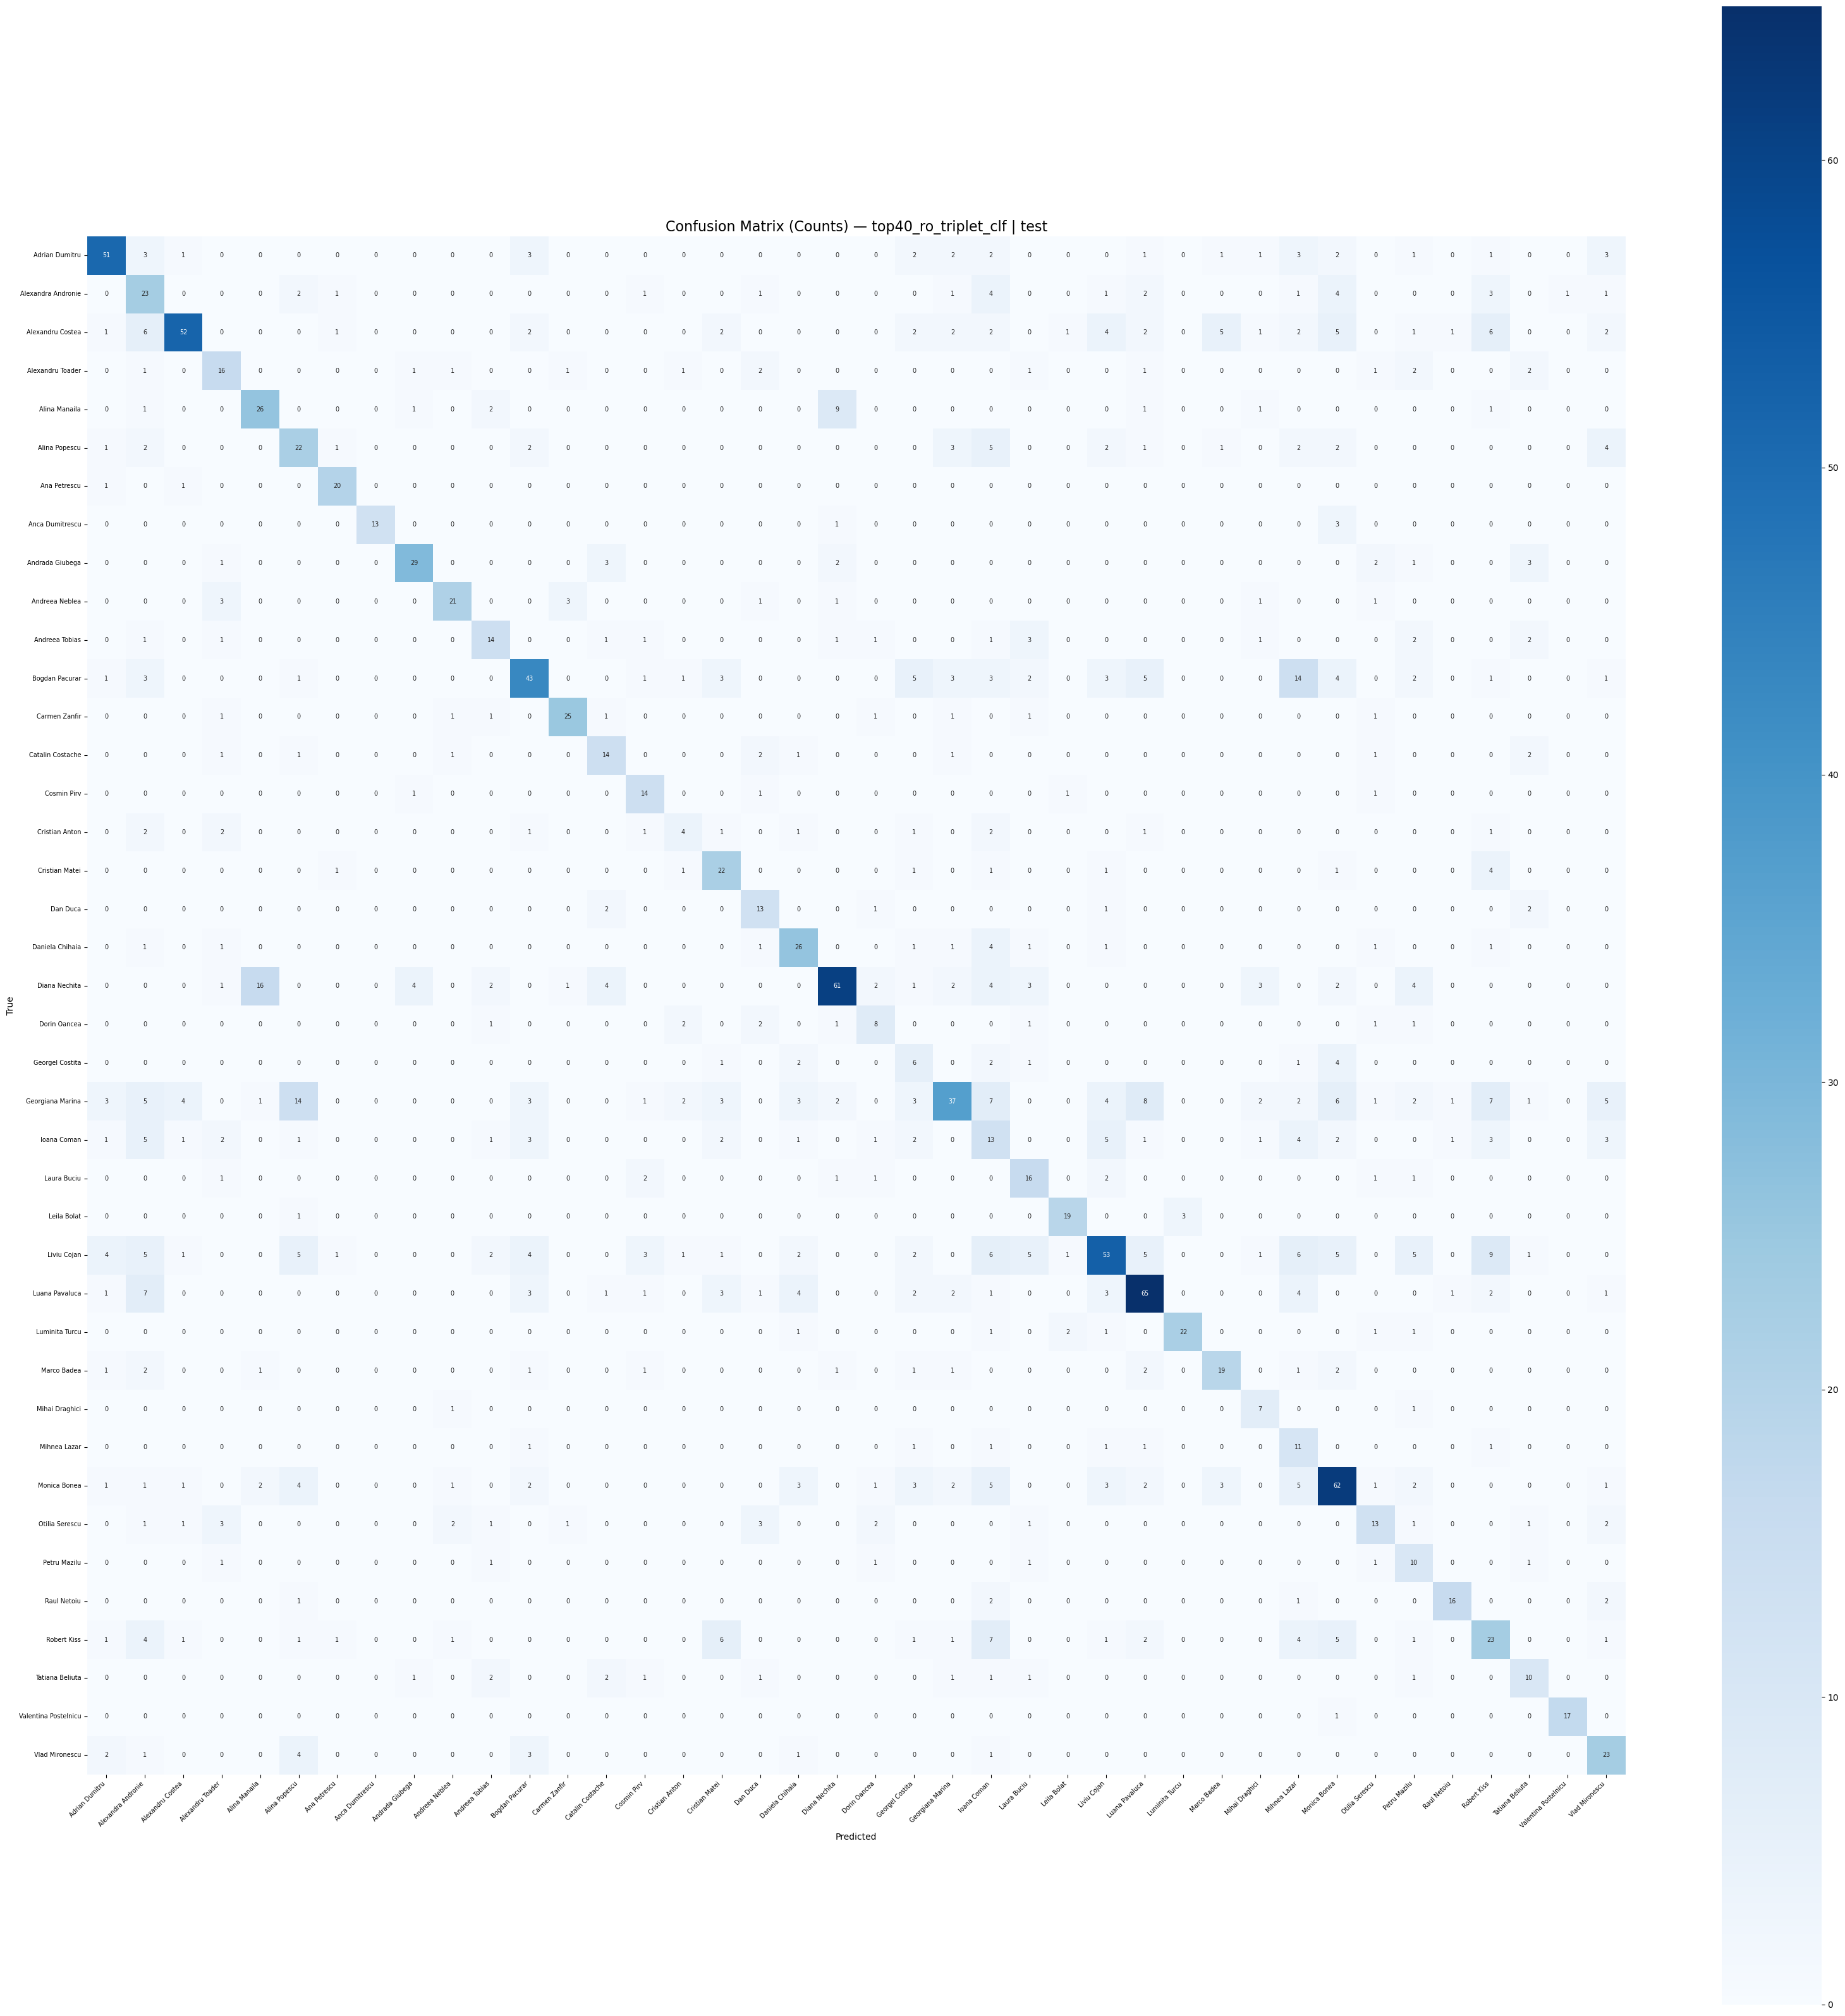

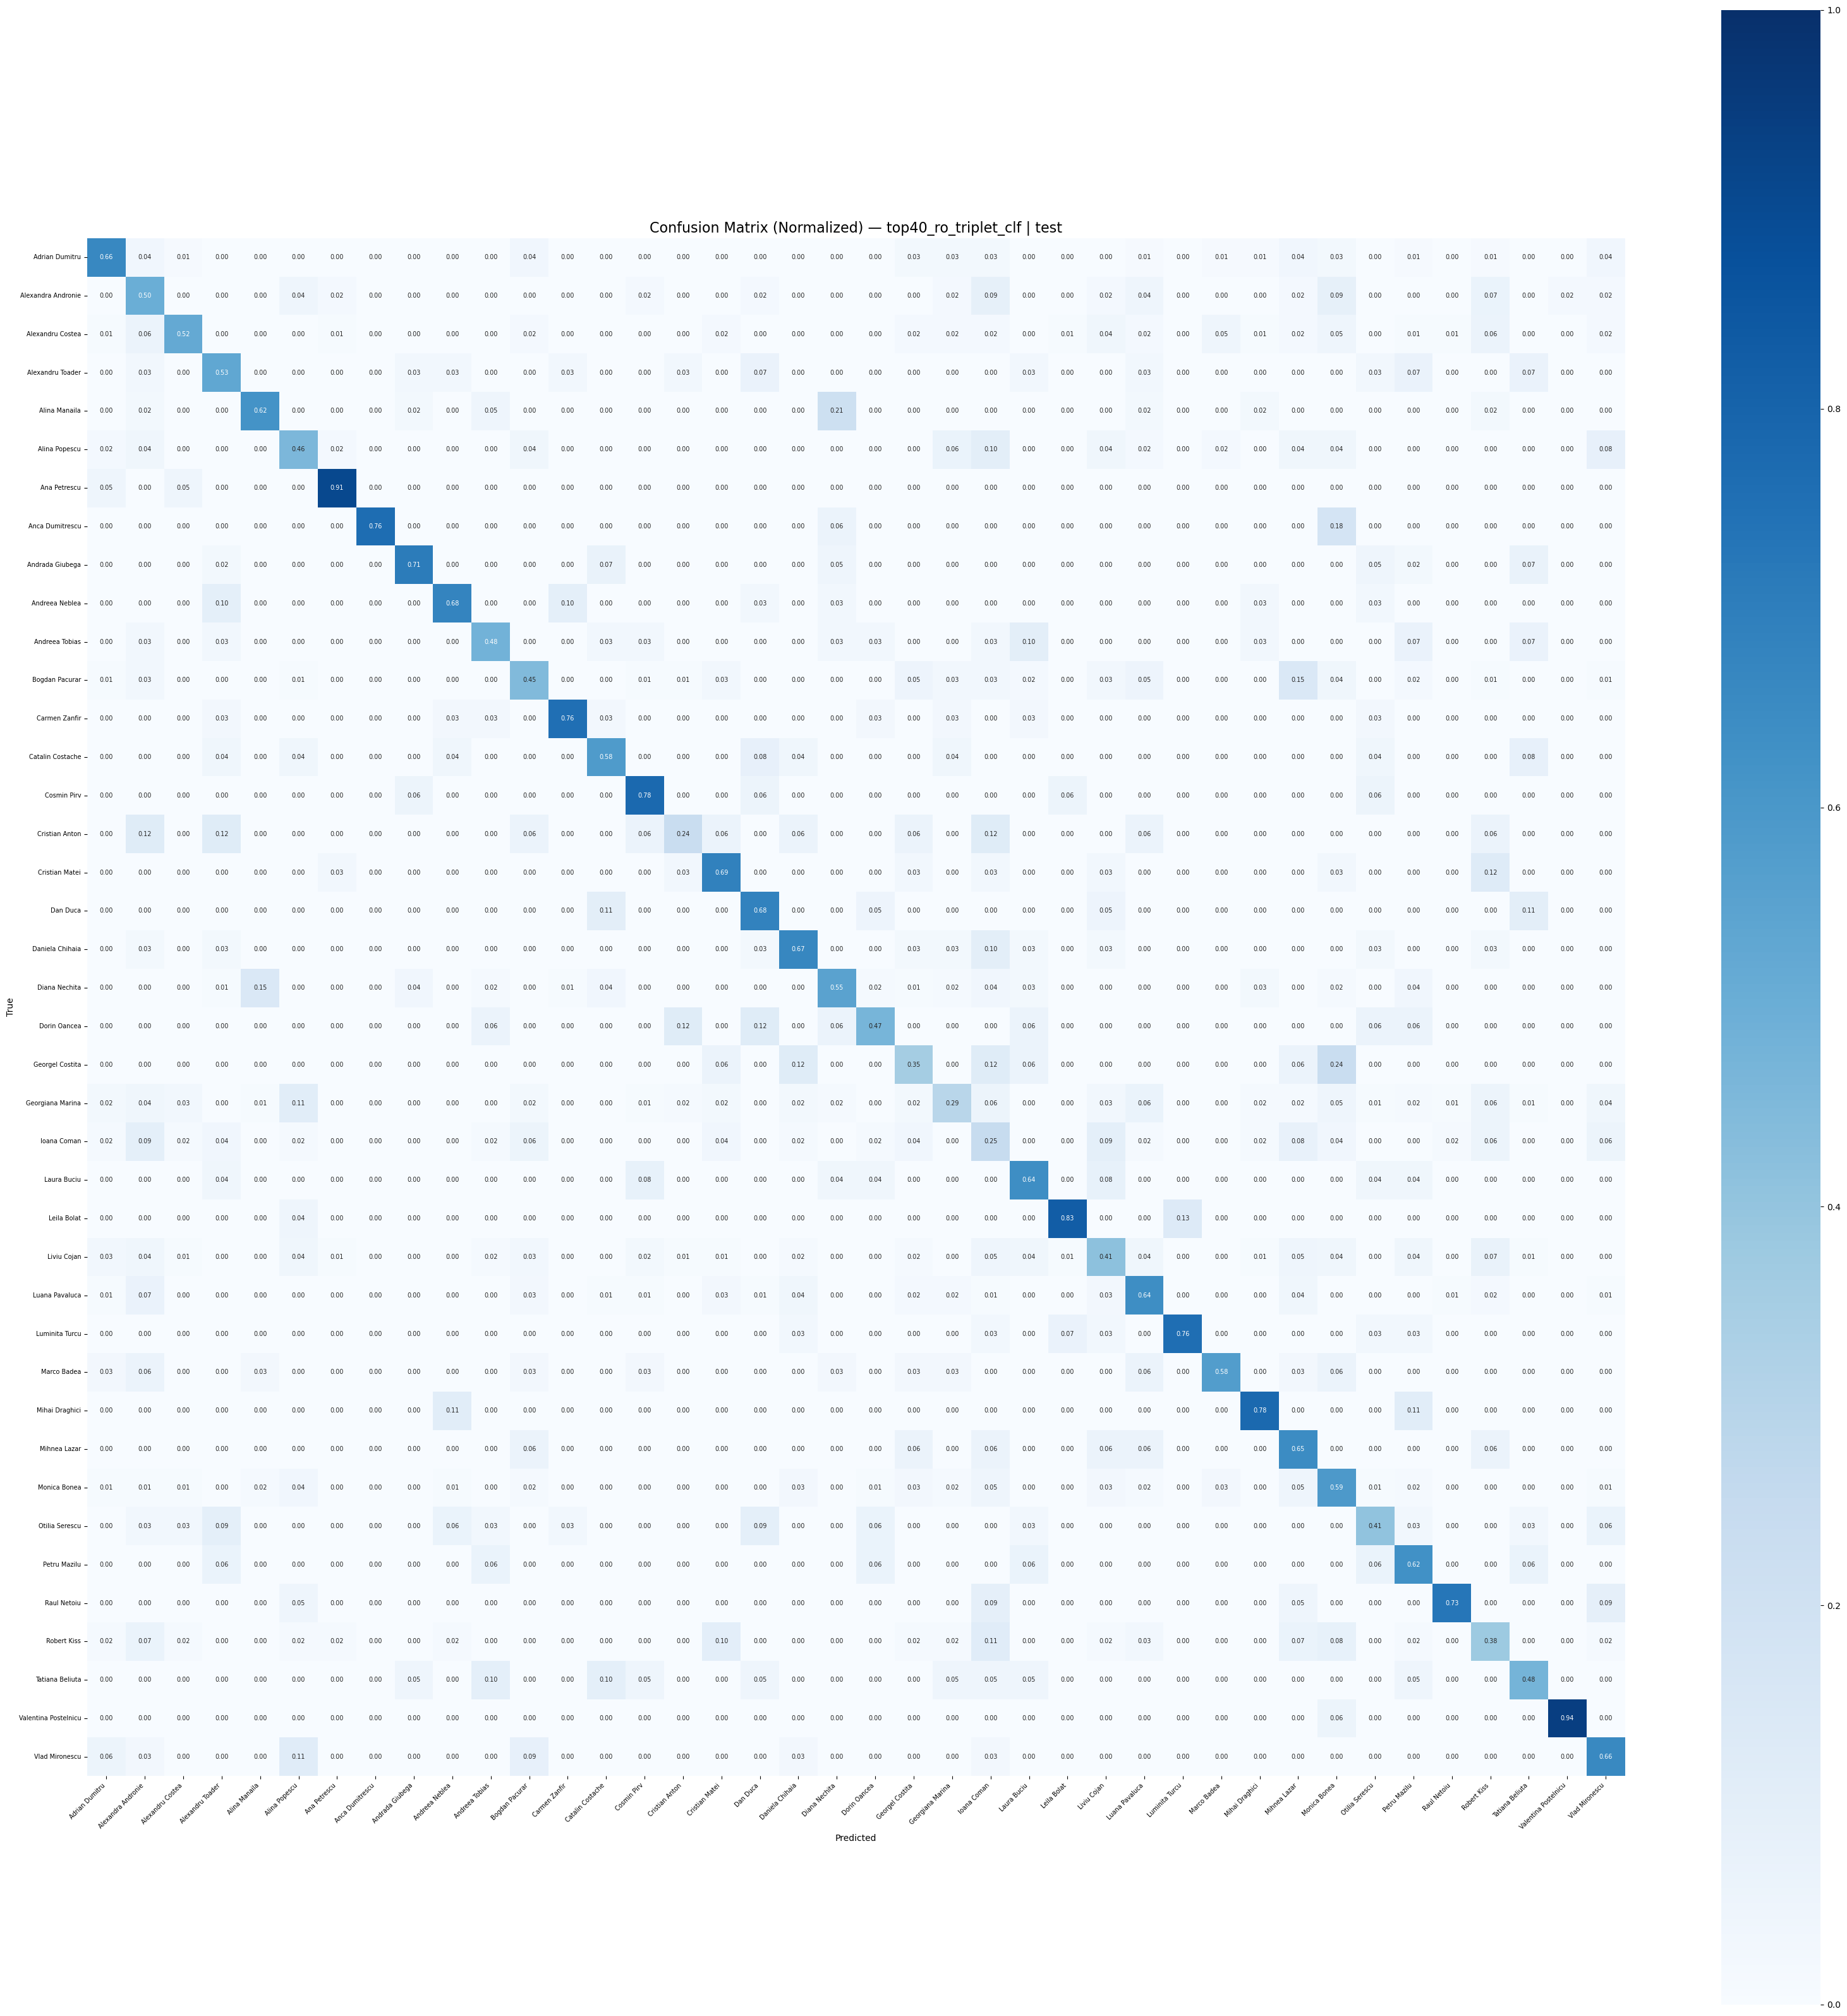

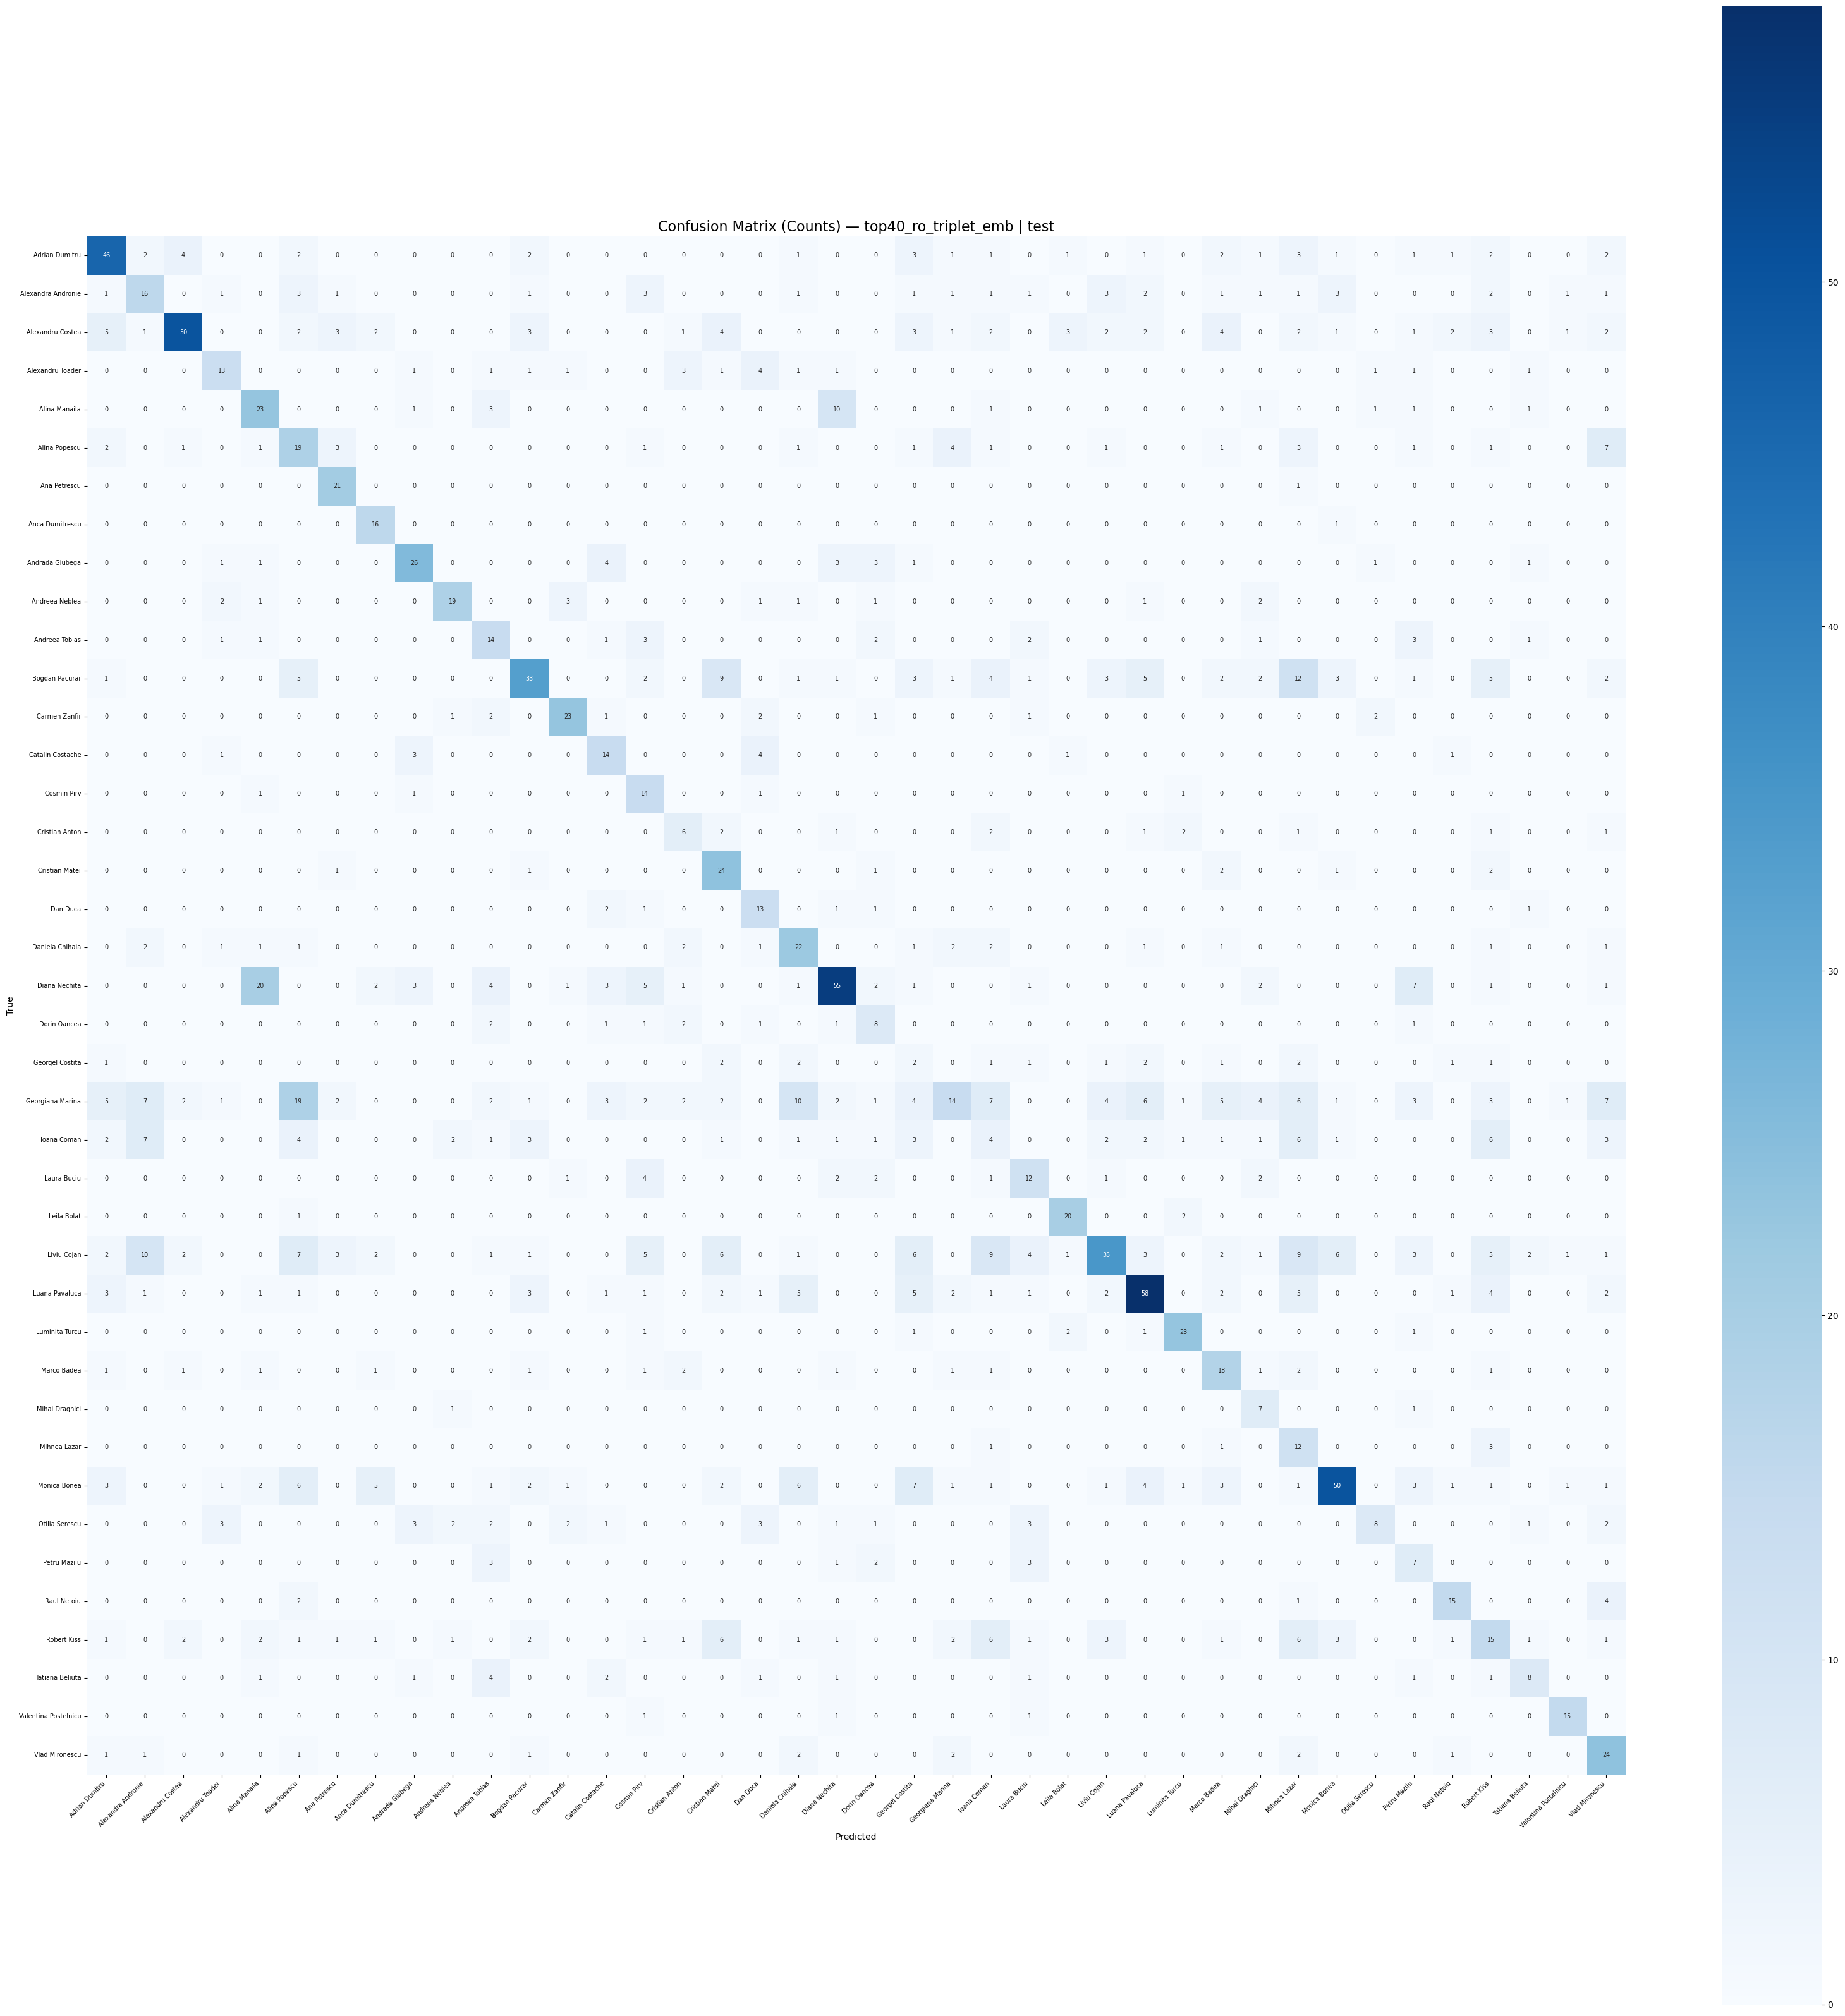

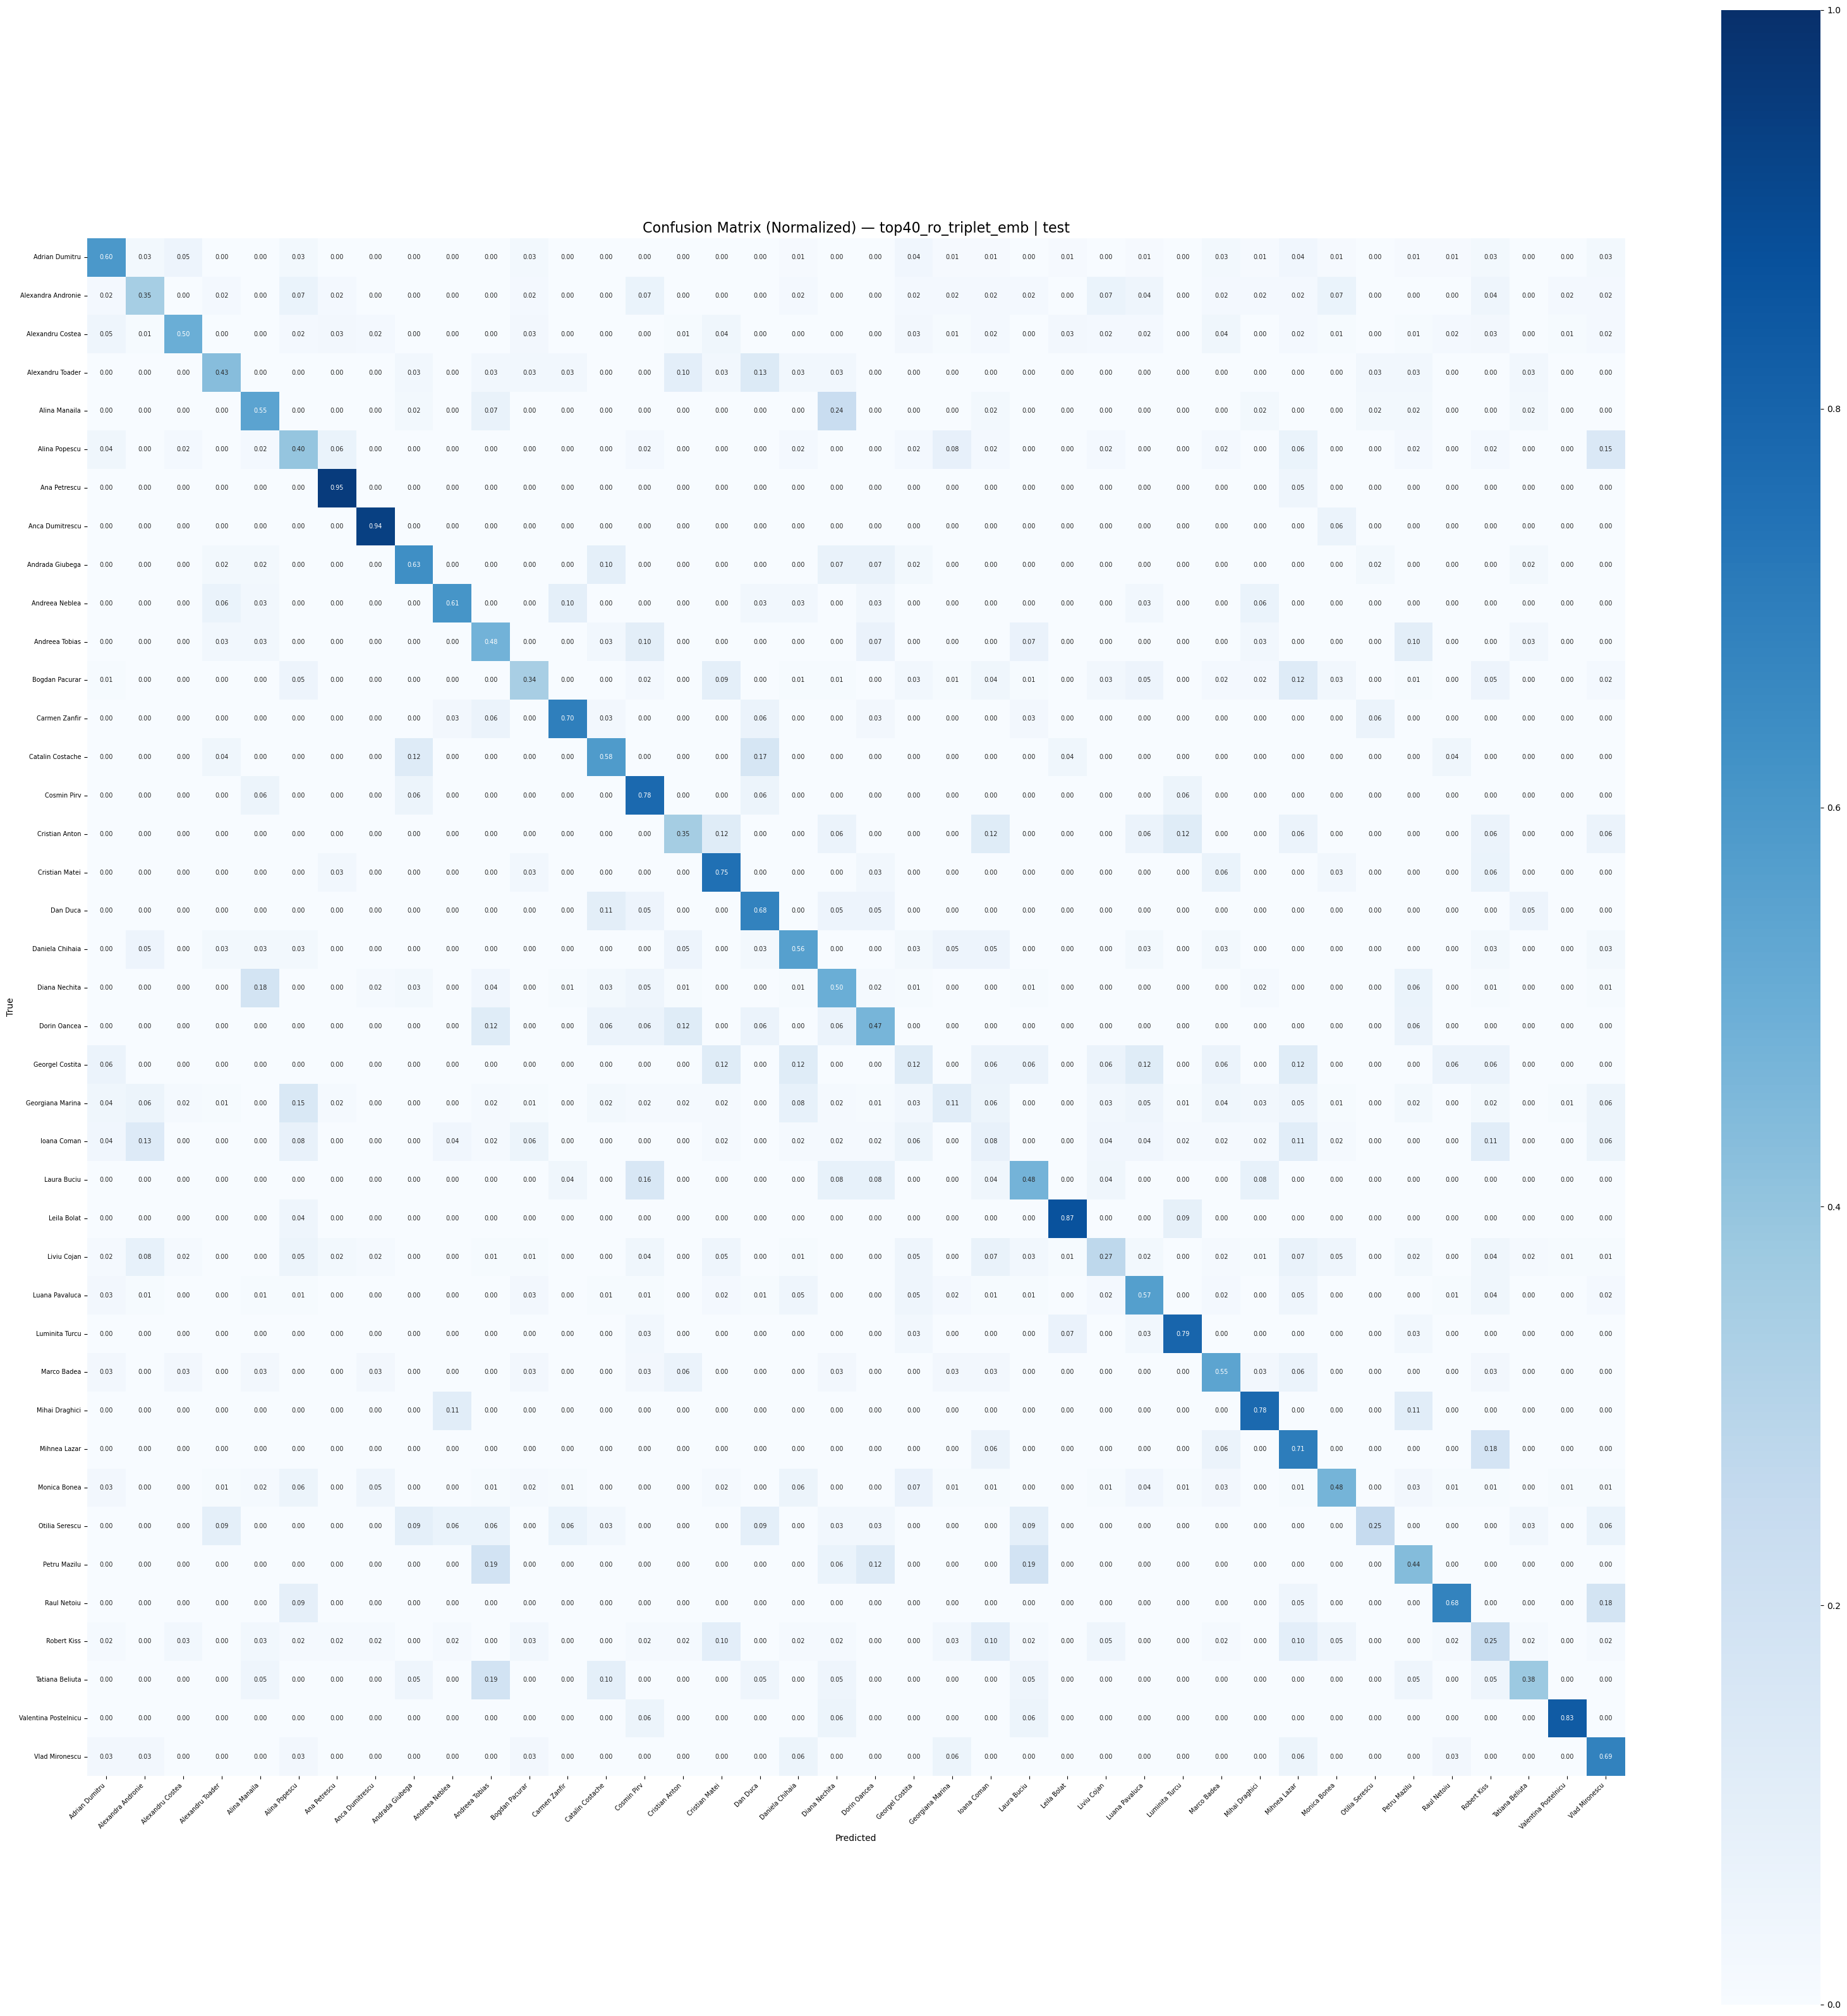


Varianta A: F1=0.5598 | Acc=0.5446
Varianta B: F1=0.4747 | Acc=0.4668


In [53]:
# test
model_path_ro40 = "outputs_contrastive_2/top40_ro/best_triplet_top40_ro.pt"
results = evaluate_model(
    model_path_ro40, le,
    texts_test, y_test,
    dataset_name="top40_ro"
)

In [54]:
# extract train doc embeddings
extract_train_doc_embeddings(
    model_path_ro40,
    train_df,
    le,
    save_path=os.path.join(
        OUTPUT_DIR,
        "top40_ro",
        "train_doc_embeddings.npz"
    ),
    tokenizer=tokenizer,
    device=device
)
# estimez cam 40 de minute 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_2/top40_ro/best_triplet_top40_ro.pt
Texte train: 66991

=== Doc Embeddings (train) ===
  0/66991
  100/66991
  200/66991
  300/66991
  400/66991
  500/66991
  600/66991
  700/66991
  800/66991
  900/66991
  1000/66991
  1100/66991
  1200/66991
  1300/66991
  1400/66991
  1500/66991
  1600/66991
  1700/66991
  1800/66991
  1900/66991
  2000/66991
  2100/66991
  2200/66991
  2300/66991
  2400/66991
  2500/66991
  2600/66991
  2700/66991
  2800/66991
  2900/66991
  3000/66991
  3100/66991
  3200/66991
  3300/66991
  3400/66991
  3500/66991
  3600/66991
  3700/66991
  3800/66991
  3900/66991
  4000/66991
  4100/66991
  4200/66991
  4300/66991
  4400/66991
  4500/66991
  4600/66991
  4700/66991
  4800/66991
  4900/66991
  5000/66991
  5100/66991
  5200/66991
  5300/66991
  5400/66991
  5500/66991
  5600/66991
  5700/66991
  5800/66991
  5900/66991
  6000/66991
  6100/66991
  6200/66991
  6300/66991
  6400/66991
  6500/66991
  6600/66991
  6700/66991
  680

In [28]:
rebuild_author_embeddings(
    model_path="outputs_contrastive_2/top40_ro/best_triplet_top40_ro.pt",
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    dataset_name="top40_ro",
    save_path="outputs_contrastive_2/top40_ro/author_embeddings_top40_ro.pt",
    tokenizer=tokenizer,
    device=device
)
# 34 minute

Texte originale: 66991
Ferestre totale: 91414
  autor 0: 3367 ferestre
  autor 1: 2519 ferestre
  autor 2: 5131 ferestre
  autor 3: 1570 ferestre
  autor 4: 2466 ferestre
  autor 5: 2201 ferestre
  autor 6: 1344 ferestre
  autor 7: 1000 ferestre
  autor 8: 2075 ferestre
  autor 9: 993 ferestre
  autor 10: 1494 ferestre
  autor 11: 5211 ferestre
  autor 12: 1487 ferestre
  autor 13: 1064 ferestre
  autor 14: 1084 ferestre
  autor 15: 1305 ferestre
  autor 16: 1475 ferestre
  autor 17: 710 ferestre
  autor 18: 2074 ferestre
  autor 19: 5076 ferestre
  autor 20: 1108 ferestre
  autor 21: 881 ferestre
  autor 22: 6331 ferestre
  autor 23: 2930 ferestre
  autor 24: 1339 ferestre
  autor 25: 901 ferestre
  autor 26: 6011 ferestre
  autor 27: 5938 ferestre
  autor 28: 1057 ferestre
  autor 29: 2762 ferestre
  autor 30: 681 ferestre
  autor 31: 1363 ferestre
  autor 32: 5379 ferestre
  autor 33: 1209 ferestre
  autor 34: 1006 ferestre
  autor 35: 1804 ferestre
  autor 36: 3161 ferestre
  autor

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Adrian Dumitru: 3367 ferestre
  Alexandra Andronie: 2519 ferestre
  Alexandru Costea: 5131 ferestre
  Alexandru Toader: 1570 ferestre
  Alina Manaila: 2466 ferestre
  Alina Popescu: 2201 ferestre
  Ana Petrescu: 1344 ferestre
  Anca Dumitrescu: 1000 ferestre
  Andrada Giubega: 2075 ferestre
  Andreea Neblea: 993 ferestre
  Andreea Tobias: 1494 ferestre
  Bogdan Pacurar: 5211 ferestre
  Carmen Zanfir: 1487 ferestre
  Catalin Costache: 1064 ferestre
  Cosmin Pirv: 1084 ferestre
  Cristian Anton: 1305 ferestre
  Cristian Matei: 1475 ferestre
  Dan Duca: 710 ferestre
  Daniela Chihaia: 2074 ferestre
  Diana Nechita: 5076 ferestre
  Dorin Oancea: 1108 ferestre
  Georgel Costita: 881 ferestre
  Georgiana Marina: 6331 ferestre
  Ioana Coman: 2930 ferestre
  Laura Buciu: 1339 ferestre
  Leila Bolat: 901 ferestre
  Liviu Cojan: 6011 ferestre
  Luana Pavaluca: 5938 ferestre
  Luminita Turcu: 1057 ferestre
  Marco Badea: 2762 ferestre
  Mihai Draghici: 681 ferestre
  Mihnea Lazar: 1363 ferestre

In [ ]:
results = implement_contrastive(
    train_df,
    val_df,
    test_df,
    "top40_ro"
)
# 530 minute


=== Pregatire date ===
Texte originale: 66991
Ferestre totale: 91414
  autor 0: 3367 ferestre
  autor 1: 2519 ferestre
  autor 2: 5131 ferestre
  autor 3: 1570 ferestre
  autor 4: 2466 ferestre
  autor 5: 2201 ferestre
  autor 6: 1344 ferestre
  autor 7: 1000 ferestre
  autor 8: 2075 ferestre
  autor 9: 993 ferestre
  autor 10: 1494 ferestre
  autor 11: 5211 ferestre
  autor 12: 1487 ferestre
  autor 13: 1064 ferestre
  autor 14: 1084 ferestre
  autor 15: 1305 ferestre
  autor 16: 1475 ferestre
  autor 17: 710 ferestre
  autor 18: 2074 ferestre
  autor 19: 5076 ferestre
  autor 20: 1108 ferestre
  autor 21: 881 ferestre
  autor 22: 6331 ferestre
  autor 23: 2930 ferestre
  autor 24: 1339 ferestre
  autor 25: 901 ferestre
  autor 26: 6011 ferestre
  autor 27: 5938 ferestre
  autor 28: 1057 ferestre
  autor 29: 2762 ferestre
  autor 30: 681 ferestre
  autor 31: 1363 ferestre
  autor 32: 5379 ferestre
  autor 33: 1209 ferestre
  autor 34: 1006 ferestre
  autor 35: 1804 ferestre
  autor 3

Loading weights: 0it [00:00, ?it/s]

[transformers] BertModel LOAD REPORT from: iliemihai/sentence-bert-base-romanian-uncased-v1
Key                                                            | Status     | 
---------------------------------------------------------------+------------+-
model.encoder.layer.{0...23}.attention.self.value.weight       | UNEXPECTED | 
model.encoder.layer.{0...23}.output.dense.weight               | UNEXPECTED | 
model.encoder.layer.{0...23}.intermediate.dense.bias           | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.key.bias           | UNEXPECTED | 
model.encoder.layer.{0...23}.intermediate.dense.weight         | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.output.dense.bias       | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.output.LayerNorm.weight | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.output.LayerNorm.bias   | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.query.weight       | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.


==========CALCULARE PROFILE AUTORI==============


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

...

Train - loss: 0.9345 CE: 0.8710 Triplet: 0.2115 F1: 0.7895
Val  - loss: 1.6272 F1: 0.5697 Acc: 0.5542

Epoch 15/15
Autori: 40
Samples per autor: 500
Total triplete: 20000
Batches (bs=40): 500
Batch size: 40
Batches per epoca: 500


/tmp/ipykernel_94602/3842971621.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_94602/3842971621.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


  Batch 0/500 loss: 1.2813 CE: 1.2123 Triplet: 0.2302
  Batch 100/500 loss: 0.9513 CE: 0.8795 Triplet: 0.2395
  Batch 200/500 loss: 0.6269 CE: 0.5601 Triplet: 0.2224
  Batch 300/500 loss: 1.3261 CE: 1.2513 Triplet: 0.2495
  Batch 400/500 loss: 0.8398 CE: 0.7942 Triplet: 0.1519


/tmp/ipykernel_94602/4053161492.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_94602/531917180.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Train - loss: 0.9209 CE: 0.8585 Triplet: 0.2080 F1: 0.7795
Val  - loss: 1.6257 F1: 0.5720 Acc: 0.5525
  Salvat (F1=0.5720)

Best Val F1: 0.5720

=== User Embeddings ===
  Adrian Dumitru: 3367 ferestre
  Alexandra Andronie: 2519 ferestre
  Alexandru Costea: 5131 ferestre
  Alexandru Toader: 1570 ferestre
  Alina Manaila: 2466 ferestre
  Alina Popescu: 2201 ferestre
  Ana Petrescu: 1344 ferestre
  Anca Dumitrescu: 1000 ferestre
  Andrada Giubega: 2075 ferestre
  Andreea Neblea: 993 ferestre
  Andreea Tobias: 1494 ferestre
  Bogdan Pacurar: 5211 ferestre
  Carmen Zanfir: 1487 ferestre
  Catalin Costache: 1064 ferestre
  Cosmin Pirv: 1084 ferestre
  Cristian Anton: 1305 ferestre
  Cristian Matei: 1475 ferestre
  Dan Duca: 710 ferestre
  Daniela Chihaia: 2074 ferestre
  Diana Nechita: 5076 ferestre
  Dorin Oancea: 1108 ferestre
  Georgel Costita: 881 ferestre
  Georgiana Marina: 6331 ferestre
  Ioana Coman: 2930 ferestre
  Laura Buciu: 1339 ferestre
  Leila Bolat: 901 ferestre
  Liviu Cojan

### top 20 MO

In [45]:
train_df = pd.read_csv("final_stilo/top20_mo_train.csv")
val_df   = pd.read_csv("final_stilo/top20_mo_val.csv")
test_df  = pd.read_csv("final_stilo/top20_mo_test.csv")

In [46]:
# prepare
le, texts_train_w, y_train_w, \
texts_val, y_val, \
texts_test, y_test, \
val_loader, test_loader = prepare_data(train_df, val_df, test_df)


=== Pregatire date ===
Texte originale: 39332
Ferestre totale: 51980
  autor 0: 1895 ferestre
  autor 1: 1131 ferestre
  autor 2: 3169 ferestre
  autor 3: 1684 ferestre
  autor 4: 2886 ferestre
  autor 5: 2841 ferestre
  autor 6: 3042 ferestre
  autor 7: 3160 ferestre
  autor 8: 1523 ferestre
  autor 9: 1248 ferestre
  autor 10: 2615 ferestre
  autor 11: 2152 ferestre
  autor 12: 3502 ferestre
  autor 13: 4018 ferestre
  autor 14: 1410 ferestre
  autor 15: 6796 ferestre
  autor 16: 3829 ferestre
  autor 17: 2341 ferestre
  autor 18: 1161 ferestre
  autor 19: 1577 ferestre
Numar autori: 20


In [ ]:
# train simplu
model, model_path, history = train_model(
    texts_train_w, y_train_w,
    val_loader, le,
    dataset_name="top20_mo"
)

In [ ]:
# testare
# asta e ok
model_path_mo20 = "outputs_contrastive_2/top20_mo/best_triplet_top20_mo.pt"
results = evaluate_model(
    model_path=model_path_mo20,
    le=le,
    texts_test=texts_test,
    y_test=y_test,
    dataset_name="top20_mo"
)
# 8 minute


Incarc embeddings...
  User embs:  20 autori
  Val embs:   (4916, 128)
  Test embs:  (4917, 128)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_2/top20_mo/best_triplet_top20_mo.pt

=== Evaluare test ===

Varianta A: Clasificator + Majority Voting
  Progress: 0/4917
  Progress: 100/4917
  Progress: 200/4917
  Progress: 300/4917
  Progress: 400/4917
  Progress: 500/4917
  Progress: 600/4917
  Progress: 700/4917
  Progress: 800/4917
  Progress: 900/4917
  Progress: 1000/4917
  Progress: 1100/4917
  Progress: 1200/4917
  Progress: 1300/4917
  Progress: 1400/4917
  Progress: 1500/4917
  Progress: 1600/4917
  Progress: 1700/4917
  Progress: 1800/4917
  Progress: 1900/4917
  Progress: 2000/4917
  Progress: 2100/4917
  Progress: 2200/4917
  Progress: 2300/4917
  Progress: 2400/4917
  Progress: 2500/4917
  Progress: 2600/4917
  Progress: 2700/4917
  Progress: 2800/4917
  Progress: 2900/4917
  Progress: 3000/4917
  Progress: 3100/4917
  Progress: 3200/4917
  Progress: 3300/4917
  Progress: 3400/4917
  Progress: 3500/4917
  Progress: 3600/4917
  Progress: 3700/4917
  Progress: 3800/4917
  Progress: 390

In [48]:
# scot embeddinguri pe document din train
extract_train_doc_embeddings(
    model_path="outputs_contrastive_2/top20_mo/best_triplet_top20_mo.pt",
    train_df=train_df,
    label_encoder=le,
    save_path=os.path.join(
        OUTPUT_DIR,
        "top20_mo",
        "train_doc_embeddings.npz"
    ),
    tokenizer=tokenizer,
    device=device
)
# 24 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_2/top20_mo/best_triplet_top20_mo.pt
Texte train: 39332

=== Doc Embeddings (train) ===
  0/39332
  100/39332
  200/39332
  300/39332
  400/39332
  500/39332
  600/39332
  700/39332
  800/39332
  900/39332
  1000/39332
  1100/39332
  1200/39332
  1300/39332
  1400/39332
  1500/39332
  1600/39332
  1700/39332
  1800/39332
  1900/39332
  2000/39332
  2100/39332
  2200/39332
  2300/39332
  2400/39332
  2500/39332
  2600/39332
  2700/39332
  2800/39332
  2900/39332
  3000/39332
  3100/39332
  3200/39332
  3300/39332
  3400/39332
  3500/39332
  3600/39332
  3700/39332
  3800/39332
  3900/39332
  4000/39332
  4100/39332
  4200/39332
  4300/39332
  4400/39332
  4500/39332
  4600/39332
  4700/39332
  4800/39332
  4900/39332
  5000/39332
  5100/39332
  5200/39332
  5300/39332
  5400/39332
  5500/39332
  5600/39332
  5700/39332
  5800/39332
  5900/39332
  6000/39332
  6100/39332
  6200/39332
  6300/39332
  6400/39332
  6500/39332
  6600/39332
  6700/39332
  680

In [ ]:
rebuild_author_embeddings(
    model_path="outputs_contrastive_2/top20_mo/best_triplet_top20_mo.pt",
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    dataset_name="top20_mo",
    save_path="outputs_contrastive_2/top20_mo/author_embeddings_top20_mo.pt",
    tokenizer=tokenizer,
    device=device
)
# 24 minute

Texte originale: 39332
Ferestre totale: 51980
  autor 0: 1895 ferestre
  autor 1: 1131 ferestre
  autor 2: 3169 ferestre
  autor 3: 1684 ferestre
  autor 4: 2886 ferestre
  autor 5: 2841 ferestre
  autor 6: 3042 ferestre
  autor 7: 3160 ferestre
  autor 8: 1523 ferestre
  autor 9: 1248 ferestre
  autor 10: 2615 ferestre
  autor 11: 2152 ferestre
  autor 12: 3502 ferestre
  autor 13: 4018 ferestre
  autor 14: 1410 ferestre
  autor 15: 6796 ferestre
  autor 16: 3829 ferestre
  autor 17: 2341 ferestre
  autor 18: 1161 ferestre
  autor 19: 1577 ferestre
Numar autori: 20

=== Author Embeddings Rebuilding...===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Aliona Ciurca: 1895 ferestre
  Ana-Maria Dolghii: 1131 ferestre
  Cristian Sava: 3169 ferestre
  Cristina Dulea: 1684 ferestre
  Cristina Mirca: 2886 ferestre
  Cristina Popescu: 2841 ferestre
  Diana Gatcan: 3042 ferestre
  Diana Severin: 3160 ferestre
  Ecaterina Arvintii: 1523 ferestre
  Malvina Cojocari: 1248 ferestre
  Marina Ciobanu: 2615 ferestre
  Maxim Stratan: 2152 ferestre
  Mihaela Conovali: 3502 ferestre
  Milena Onisim: 4018 ferestre
  Nicoleta Braghis: 1410 ferestre
  Stela Untila: 6796 ferestre
  Svetlana Cartin: 3829 ferestre
  Svetlana Cojocaru: 2341 ferestre
  Valentina Buza: 1161 ferestre
  Viorica Rusu: 1577 ferestre

 Author Embeddings salvate la: outputs_contrastive_2/top20_mo/author_embeddings_top20_mo.pt

=== Doc Embeddings (val) ===
  0/4916
  100/4916
  200/4916
  300/4916
  400/4916
  500/4916
  600/4916
  700/4916
  800/4916
  900/4916
  1000/4916
  1100/4916
  1200/4916
  1300/4916
  1400/4916
  1500/4916
  1600/4916
  1700/4916
  1800/4916
  1900/4916
 

In [ ]:
results = implement_contrastive(
    train_df,
    val_df,
    test_df,
    "top20_mo"
)
# 289 minute


=== Pregatire date ===
Texte originale: 39332
Ferestre totale: 51980
  autor 0: 1895 ferestre
  autor 1: 1131 ferestre
  autor 2: 3169 ferestre
  autor 3: 1684 ferestre
  autor 4: 2886 ferestre
  autor 5: 2841 ferestre
  autor 6: 3042 ferestre
  autor 7: 3160 ferestre
  autor 8: 1523 ferestre
  autor 9: 1248 ferestre
  autor 10: 2615 ferestre
  autor 11: 2152 ferestre
  autor 12: 3502 ferestre
  autor 13: 4018 ferestre
  autor 14: 1410 ferestre
  autor 15: 6796 ferestre
  autor 16: 3829 ferestre
  autor 17: 2341 ferestre
  autor 18: 1161 ferestre
  autor 19: 1577 ferestre
Numar autori: 20

=== Antrenare ===
Min ferestre/autor: 1131
Median ferestre/autor: 2478
Samples per author ales: 500

Samples per author: 500


Loading weights: 0it [00:00, ?it/s]

[transformers] BertModel LOAD REPORT from: iliemihai/sentence-bert-base-romanian-uncased-v1
Key                                                            | Status     | 
---------------------------------------------------------------+------------+-
model.encoder.layer.{0...23}.intermediate.dense.bias           | UNEXPECTED | 
model.encoder.layer.{0...23}.intermediate.dense.weight         | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.output.dense.bias       | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.value.weight       | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.key.weight         | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.value.bias         | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.output.LayerNorm.bias   | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.key.bias           | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.query.weight       | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.


==========CALCULARE PROFILE AUTORI==============


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

...

Train - loss: 0.6798 CE: 0.6179 Triplet: 0.2063 F1: 0.8290
Val  - loss: 1.1254 F1: 0.6497 Acc: 0.6410
  Salvat (F1=0.6497)

Epoch 15/15
Autori: 20
Samples per autor: 500
Total triplete: 10000
Batches (bs=20): 500
Batch size: 20
Batches per epoca: 500


/tmp/ipykernel_78934/3842971621.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_78934/3842971621.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


  Batch 0/500 loss: 0.8352 CE: 0.7672 Triplet: 0.2268
  Batch 100/500 loss: 0.5144 CE: 0.4269 Triplet: 0.2916
  Batch 200/500 loss: 1.2756 CE: 1.1617 Triplet: 0.3799
  Batch 300/500 loss: 0.5081 CE: 0.4623 Triplet: 0.1528
  Batch 400/500 loss: 0.7350 CE: 0.6797 Triplet: 0.1844


/tmp/ipykernel_78934/4053161492.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_78934/531917180.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Train - loss: 0.6793 CE: 0.6164 Triplet: 0.2098 F1: 0.8134
Val  - loss: 1.1058 F1: 0.6556 Acc: 0.6475
  Salvat (F1=0.6556)

Best Val F1: 0.6556

=== User Embeddings ===
  Aliona Ciurca: 1895 ferestre
  Ana-Maria Dolghii: 1131 ferestre
  Cristian Sava: 3169 ferestre
  Cristina Dulea: 1684 ferestre
  Cristina Mirca: 2886 ferestre
  Cristina Popescu: 2841 ferestre
  Diana Gatcan: 3042 ferestre
  Diana Severin: 3160 ferestre
  Ecaterina Arvintii: 1523 ferestre
  Malvina Cojocari: 1248 ferestre
  Marina Ciobanu: 2615 ferestre
  Maxim Stratan: 2152 ferestre
  Mihaela Conovali: 3502 ferestre
  Milena Onisim: 4018 ferestre
  Nicoleta Braghis: 1410 ferestre
  Stela Untila: 6796 ferestre
  Svetlana Cartin: 3829 ferestre
  Svetlana Cojocaru: 2341 ferestre
  Valentina Buza: 1161 ferestre
  Viorica Rusu: 1577 ferestre

=== Evaluare test ===
Încărcare model: outputs_contrastive_2/top20_mo/best_triplet_top20_mo.pt

Varianta A: Clasificator + Majority Voting
  Progress: 0/4917
  Progress: 100/4917
  P

### top 40 MO

In [58]:
train_df = pd.read_csv("final_stilo/top40_mo_train.csv")
val_df   = pd.read_csv("final_stilo/top40_mo_val.csv")
test_df  = pd.read_csv("final_stilo/top40_mo_test.csv")

In [59]:
# prepare
le, texts_train_w, y_train_w, \
texts_val, y_val, \
texts_test, y_test, \
val_loader, test_loader = prepare_data(train_df, val_df, test_df)


=== Pregatire date ===
Texte originale: 47215
Ferestre totale: 63722
  autor 0: 203 ferestre
  autor 1: 1892 ferestre
  autor 2: 1126 ferestre
  autor 3: 280 ferestre
  autor 4: 930 ferestre
  autor 5: 452 ferestre
  autor 6: 831 ferestre
  autor 7: 3179 ferestre
  autor 8: 1669 ferestre
  autor 9: 2883 ferestre
  autor 10: 2849 ferestre
  autor 11: 3063 ferestre
  autor 12: 3187 ferestre
  autor 13: 660 ferestre
  autor 14: 1516 ferestre
  autor 15: 143 ferestre
  autor 16: 551 ferestre
  autor 17: 759 ferestre
  autor 18: 479 ferestre
  autor 19: 1227 ferestre
  autor 20: 951 ferestre
  autor 21: 1184 ferestre
  autor 22: 2573 ferestre
  autor 23: 2155 ferestre
  autor 24: 3492 ferestre
  autor 25: 4054 ferestre
  autor 26: 1376 ferestre
  autor 27: 6863 ferestre
  autor 28: 3829 ferestre
  autor 29: 2349 ferestre
  autor 30: 1254 ferestre
  autor 31: 145 ferestre
  autor 32: 92 ferestre
  autor 33: 153 ferestre
  autor 34: 1164 ferestre
  autor 35: 364 ferestre
  autor 36: 1410 fer

In [ ]:
# train
model, model_path, history = train_model(
    texts_train_w, y_train_w,
    val_loader, le,
    dataset_name="top40_mo"
)


Incarc embeddings...
  User embs:  40 autori
  Val embs:   (5902, 128)
  Test embs:  (5902, 128)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_2/top40_mo/best_triplet_top40_mo.pt

=== Evaluare test ===

Varianta A: Clasificator + Majority Voting
  Progress: 0/5902
  Progress: 100/5902
  Progress: 200/5902
  Progress: 300/5902
  Progress: 400/5902
  Progress: 500/5902
  Progress: 600/5902
  Progress: 700/5902
  Progress: 800/5902
  Progress: 900/5902
  Progress: 1000/5902
  Progress: 1100/5902
  Progress: 1200/5902
  Progress: 1300/5902
  Progress: 1400/5902
  Progress: 1500/5902
  Progress: 1600/5902
  Progress: 1700/5902
  Progress: 1800/5902
  Progress: 1900/5902
  Progress: 2000/5902
  Progress: 2100/5902
  Progress: 2200/5902
  Progress: 2300/5902
  Progress: 2400/5902
  Progress: 2500/5902
  Progress: 2600/5902
  Progress: 2700/5902
  Progress: 2800/5902
  Progress: 2900/5902
  Progress: 3000/5902
  Progress: 3100/5902
  Progress: 3200/5902
  Progress: 3300/5902
  Progress: 3400/5902
  Progress: 3500/5902
  Progress: 3600/5902
  Progress: 3700/5902
  Progress: 3800/5902
  Progress: 390

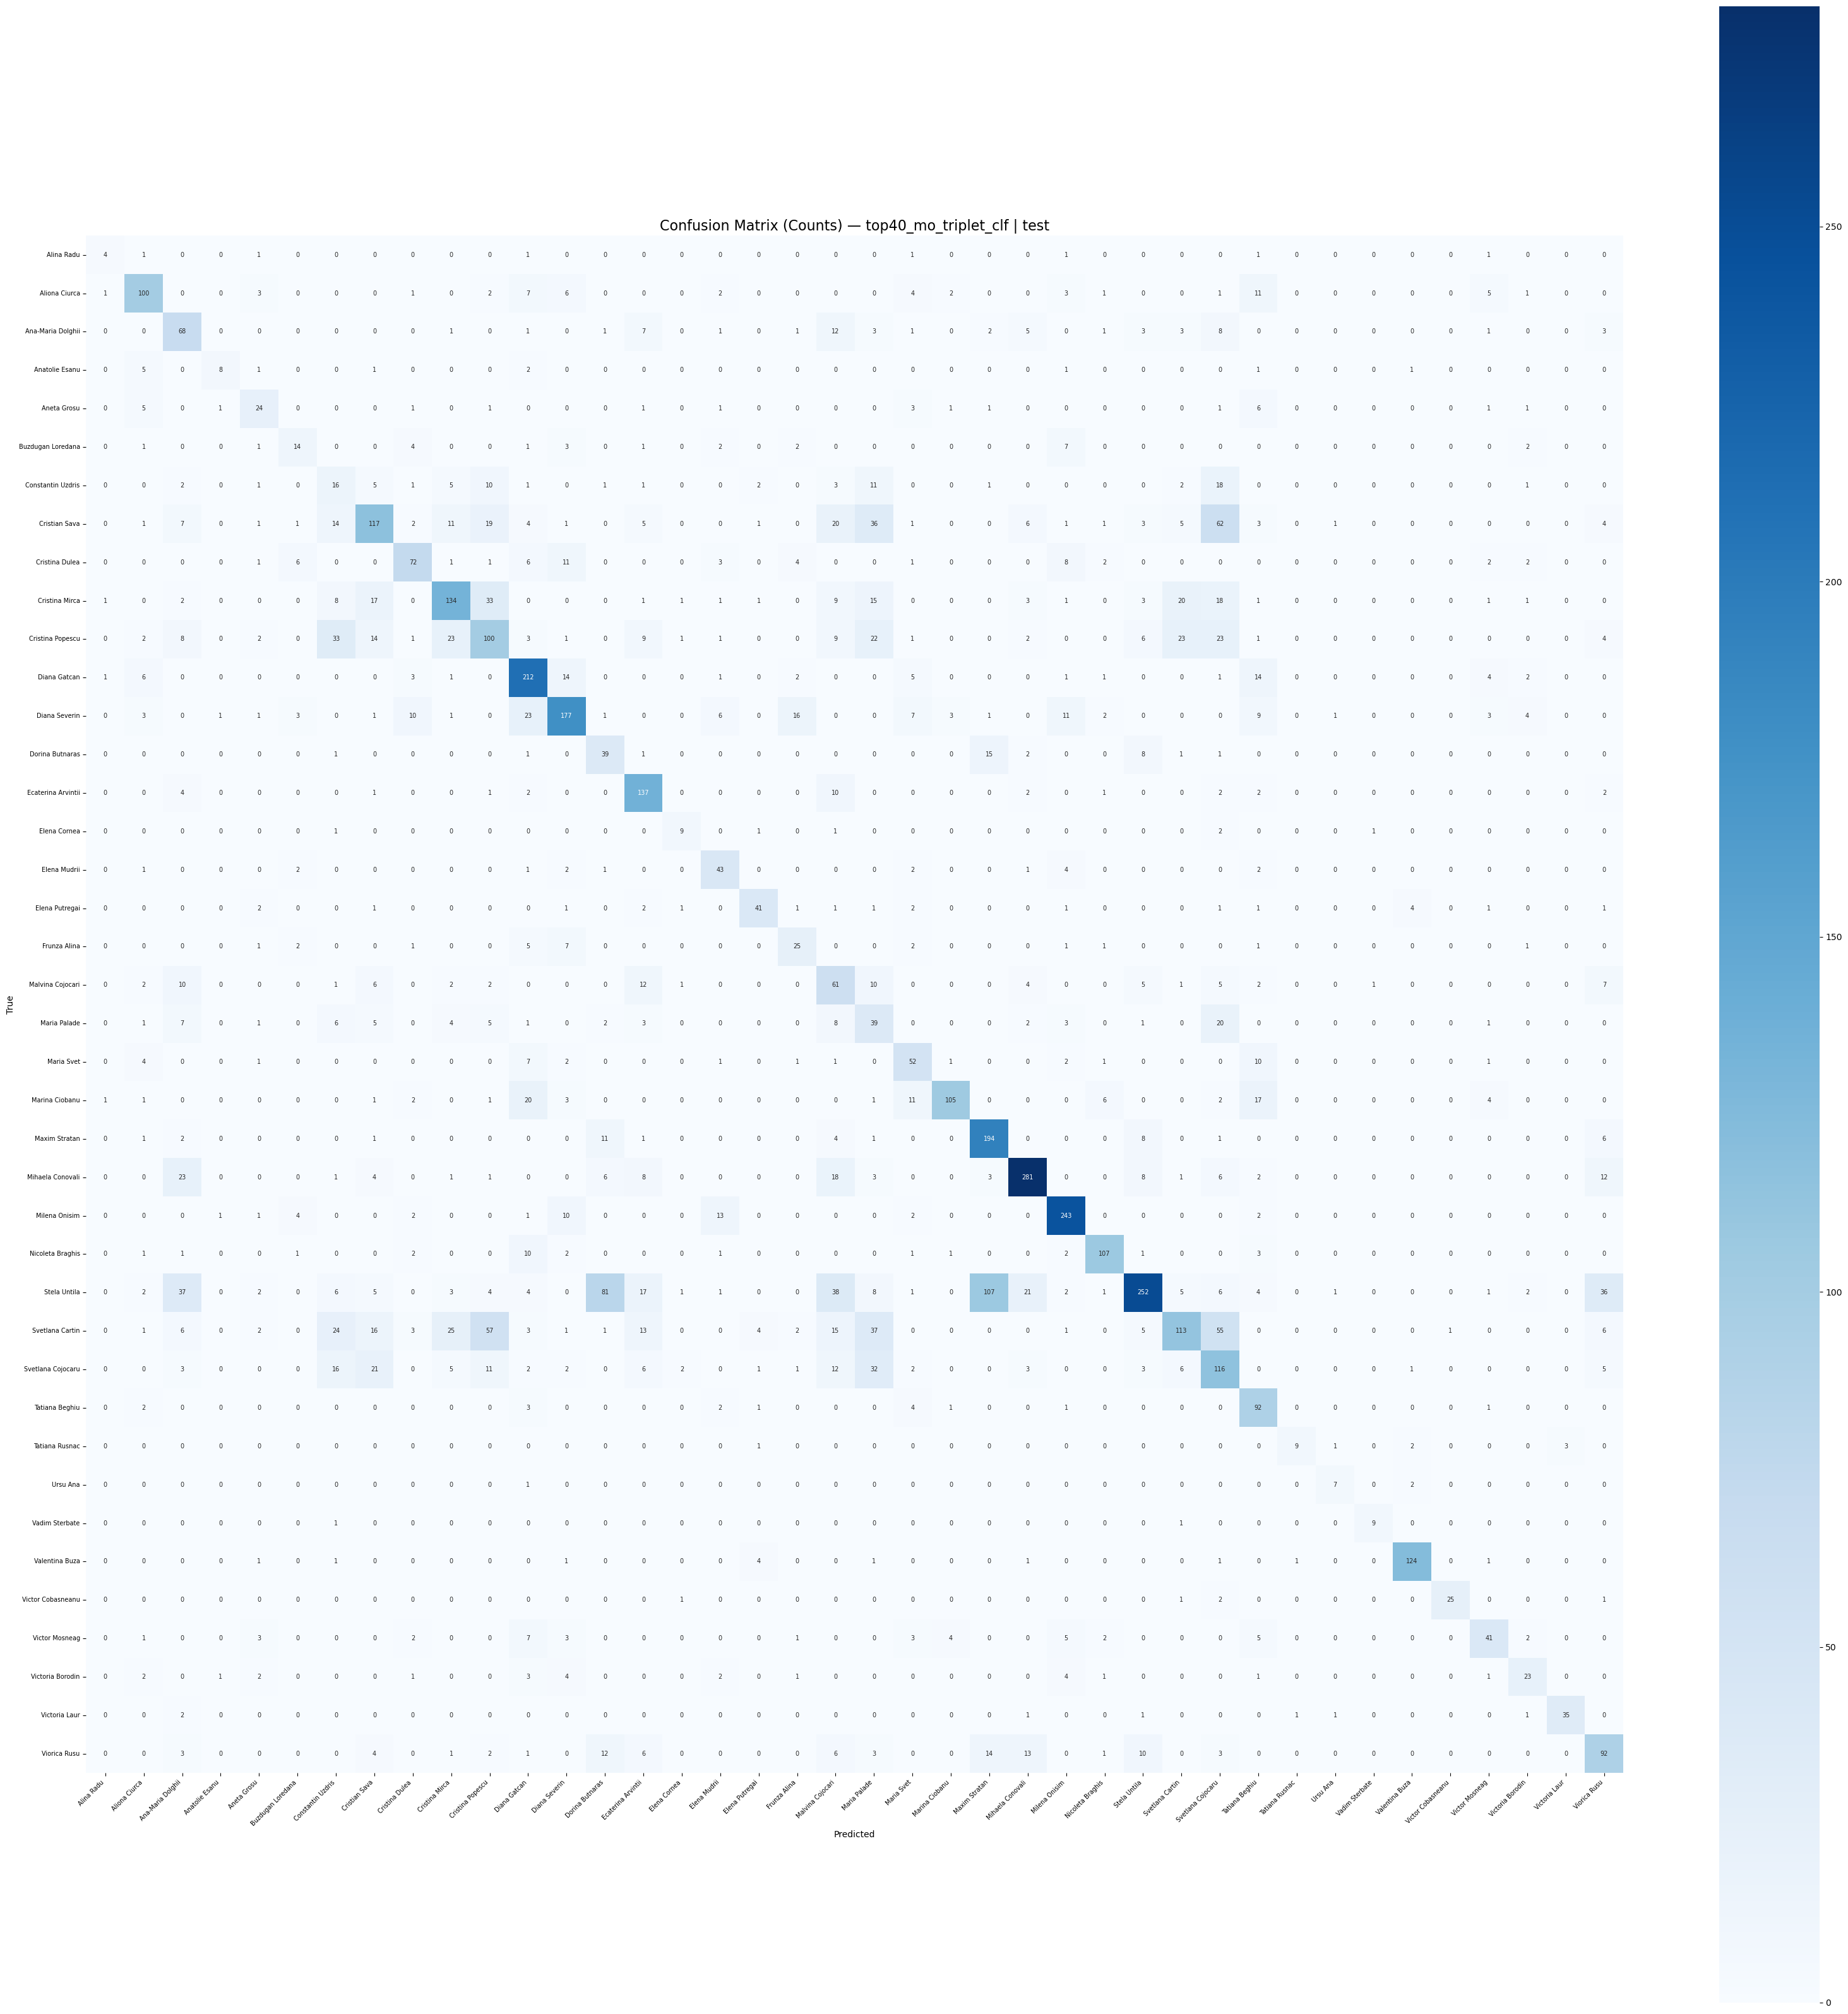

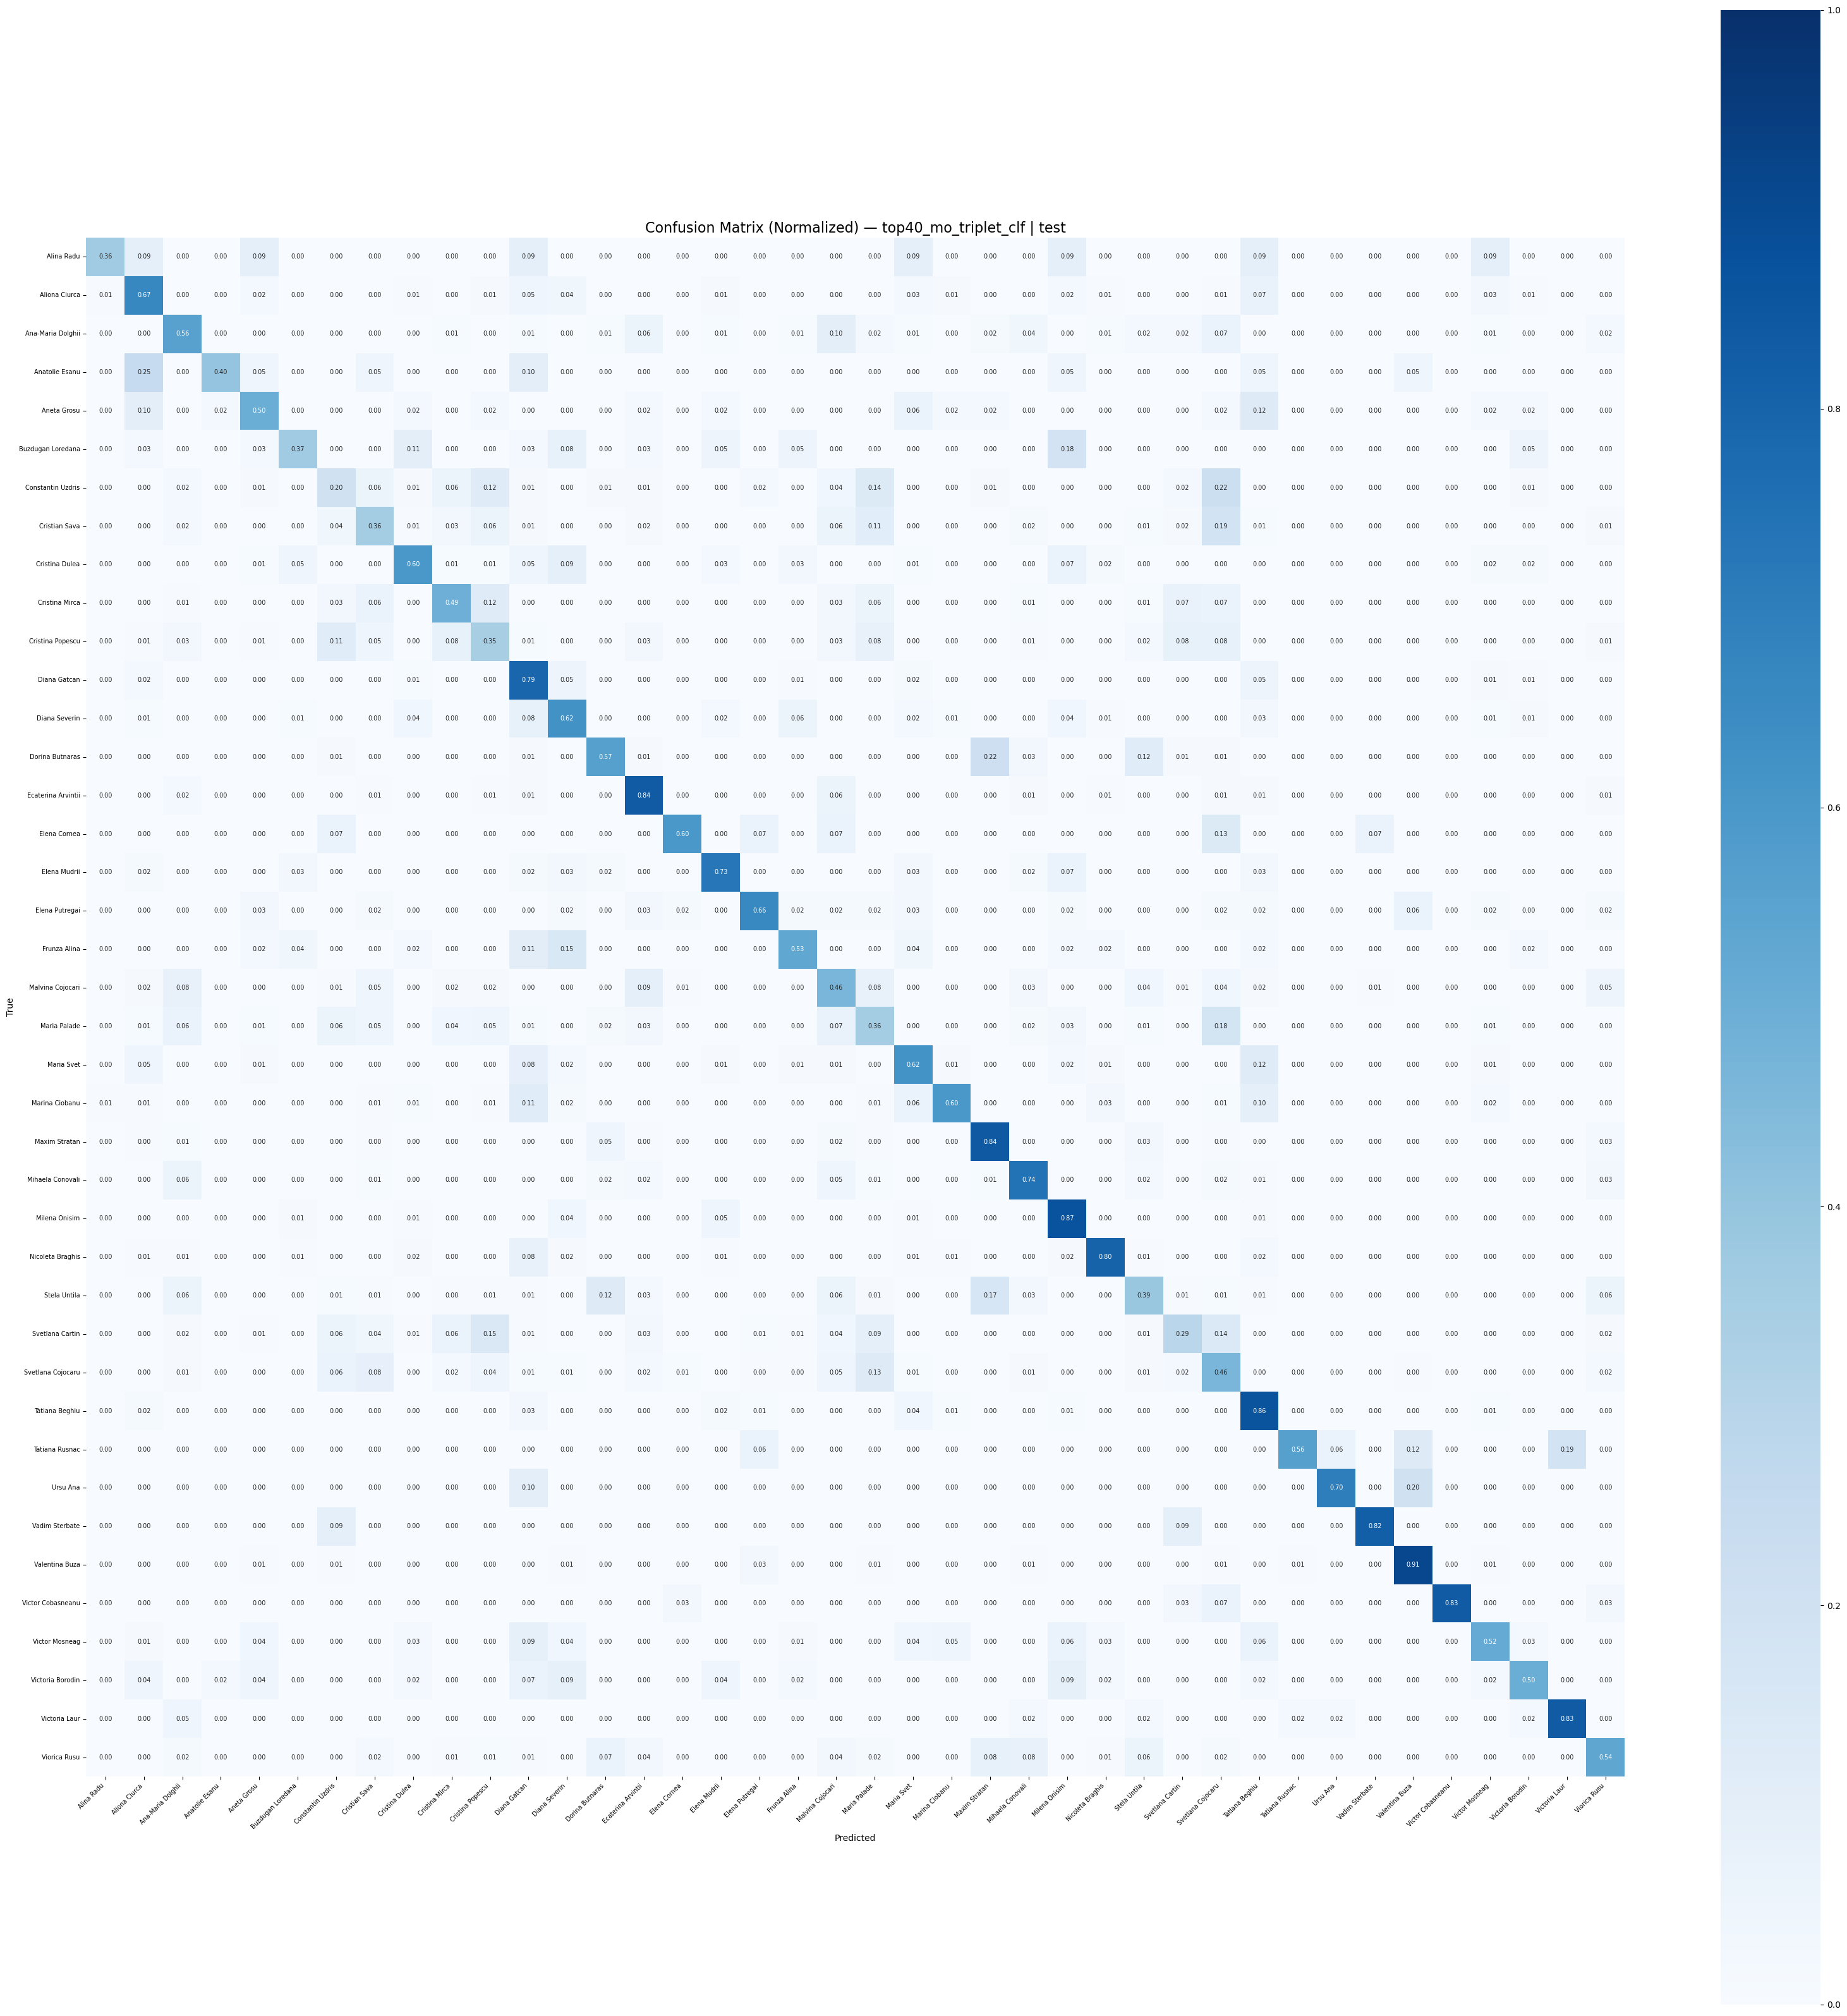

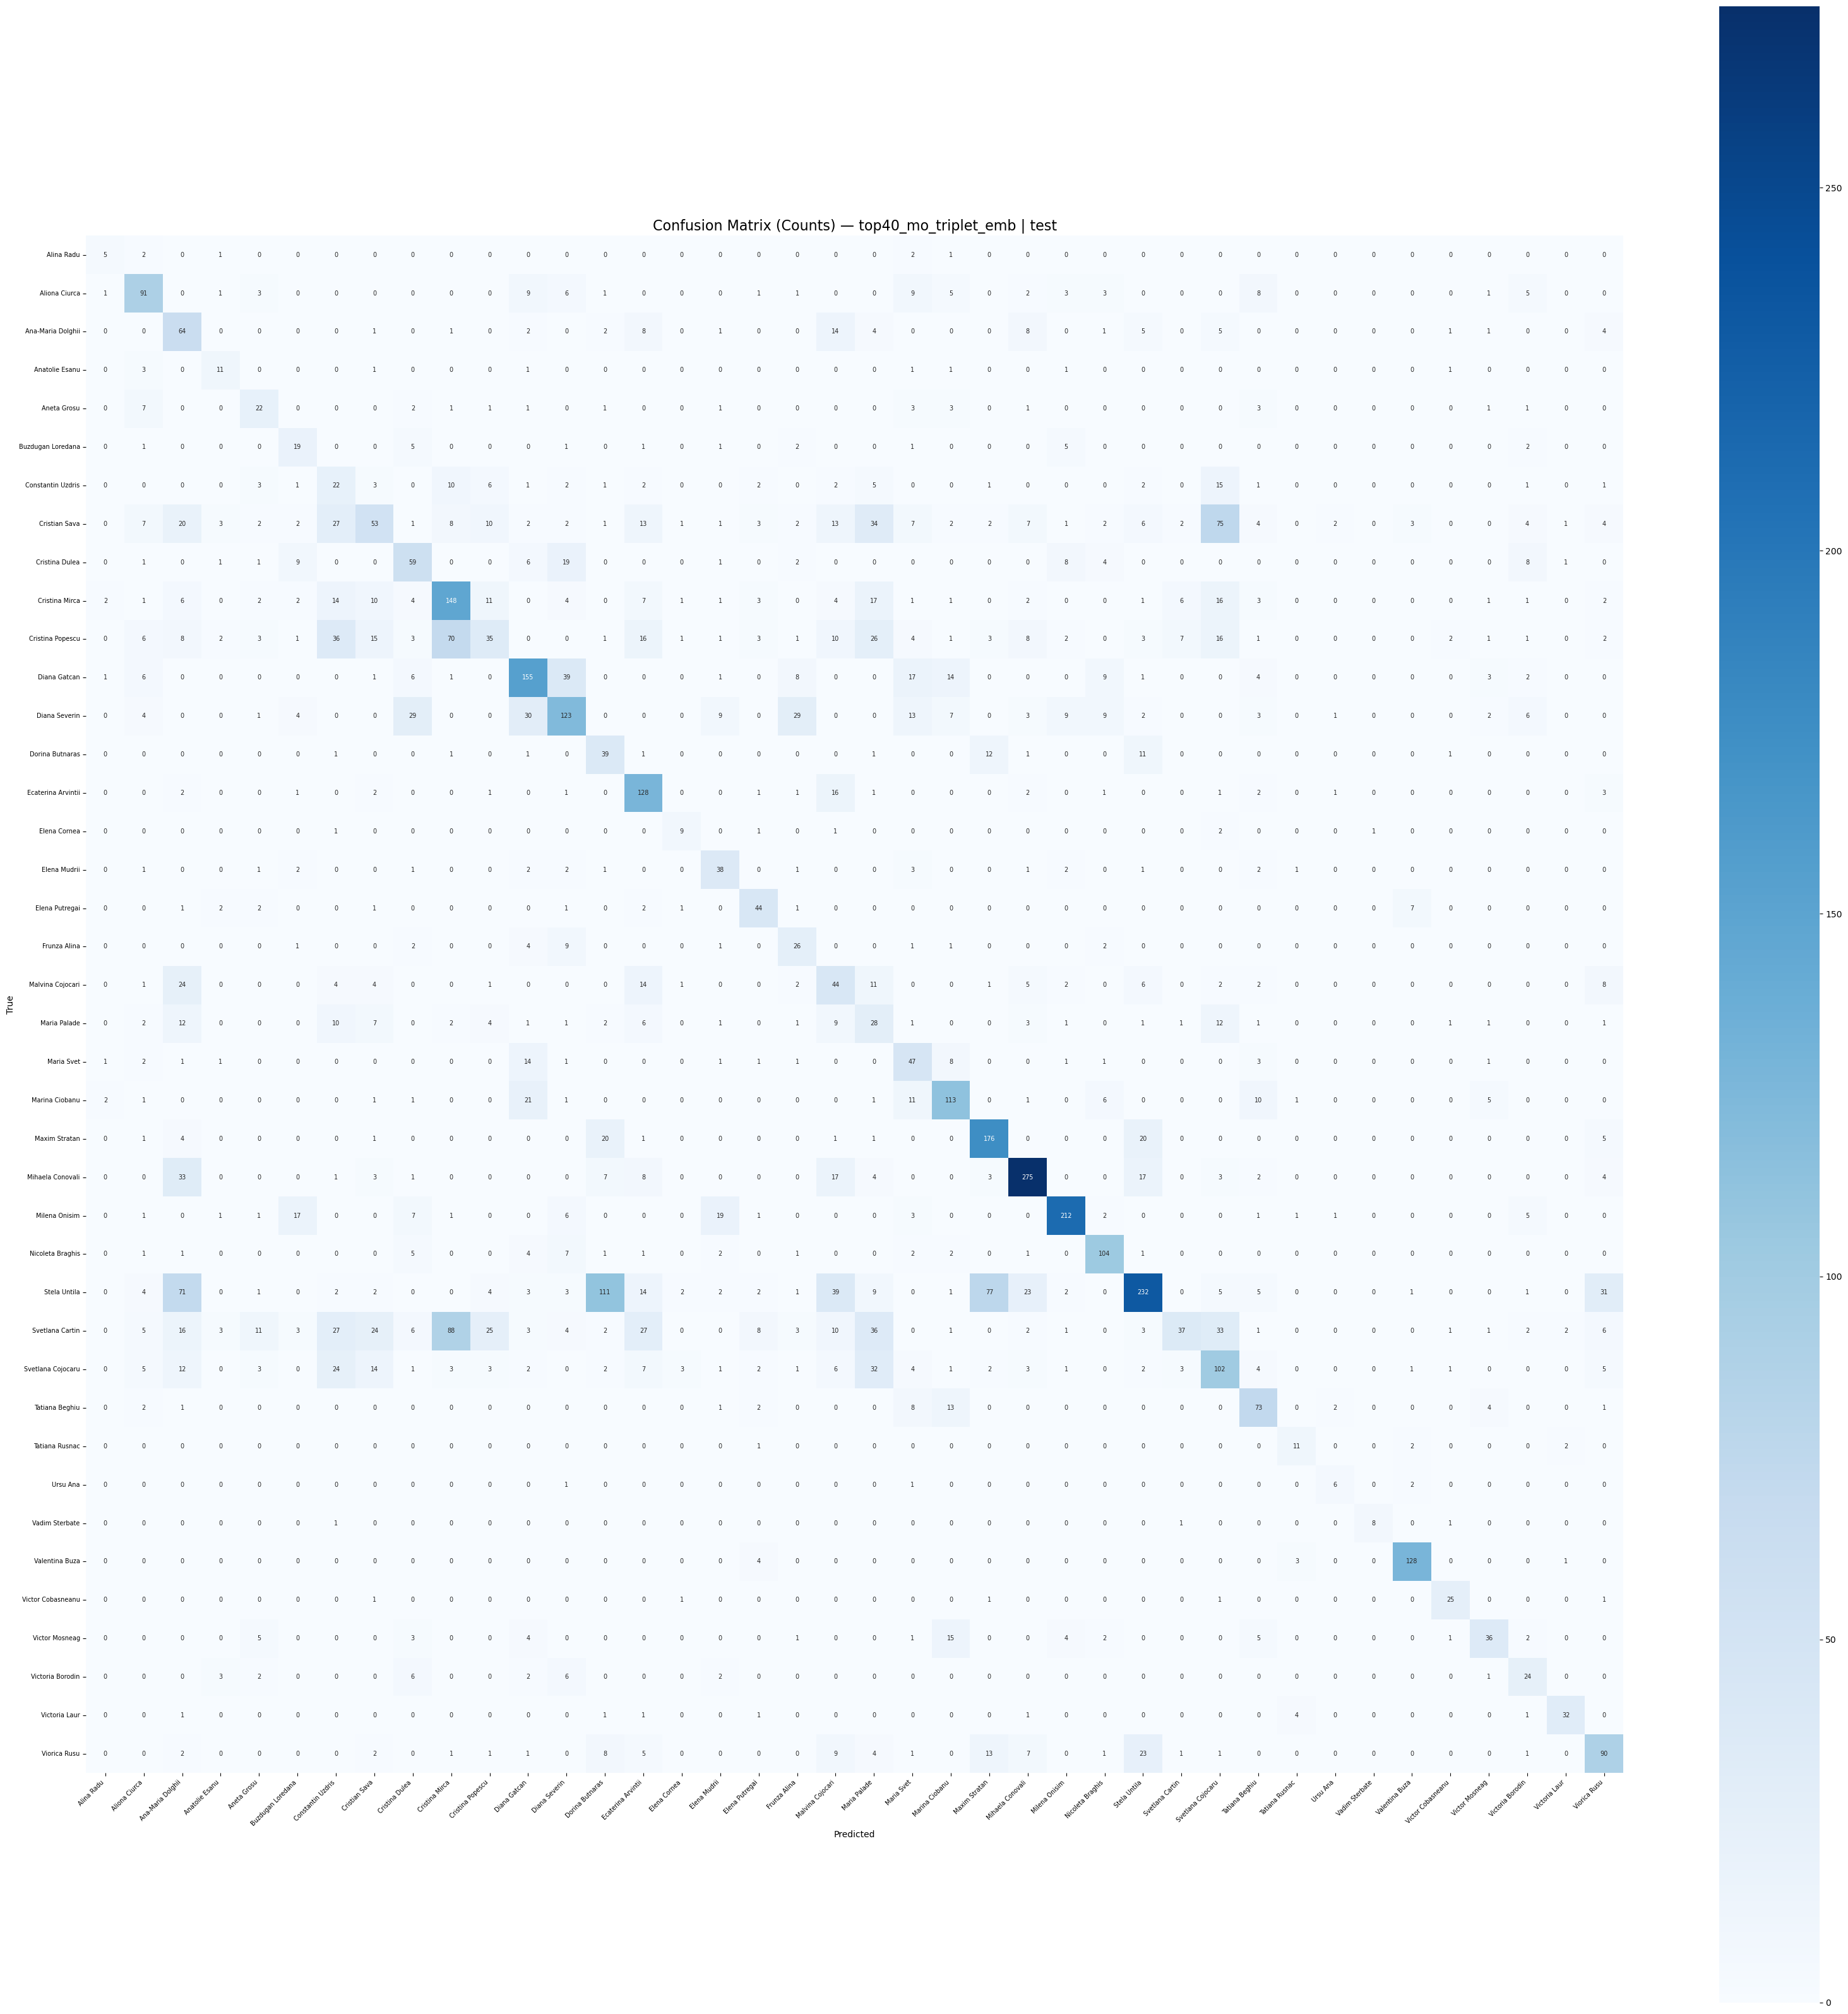

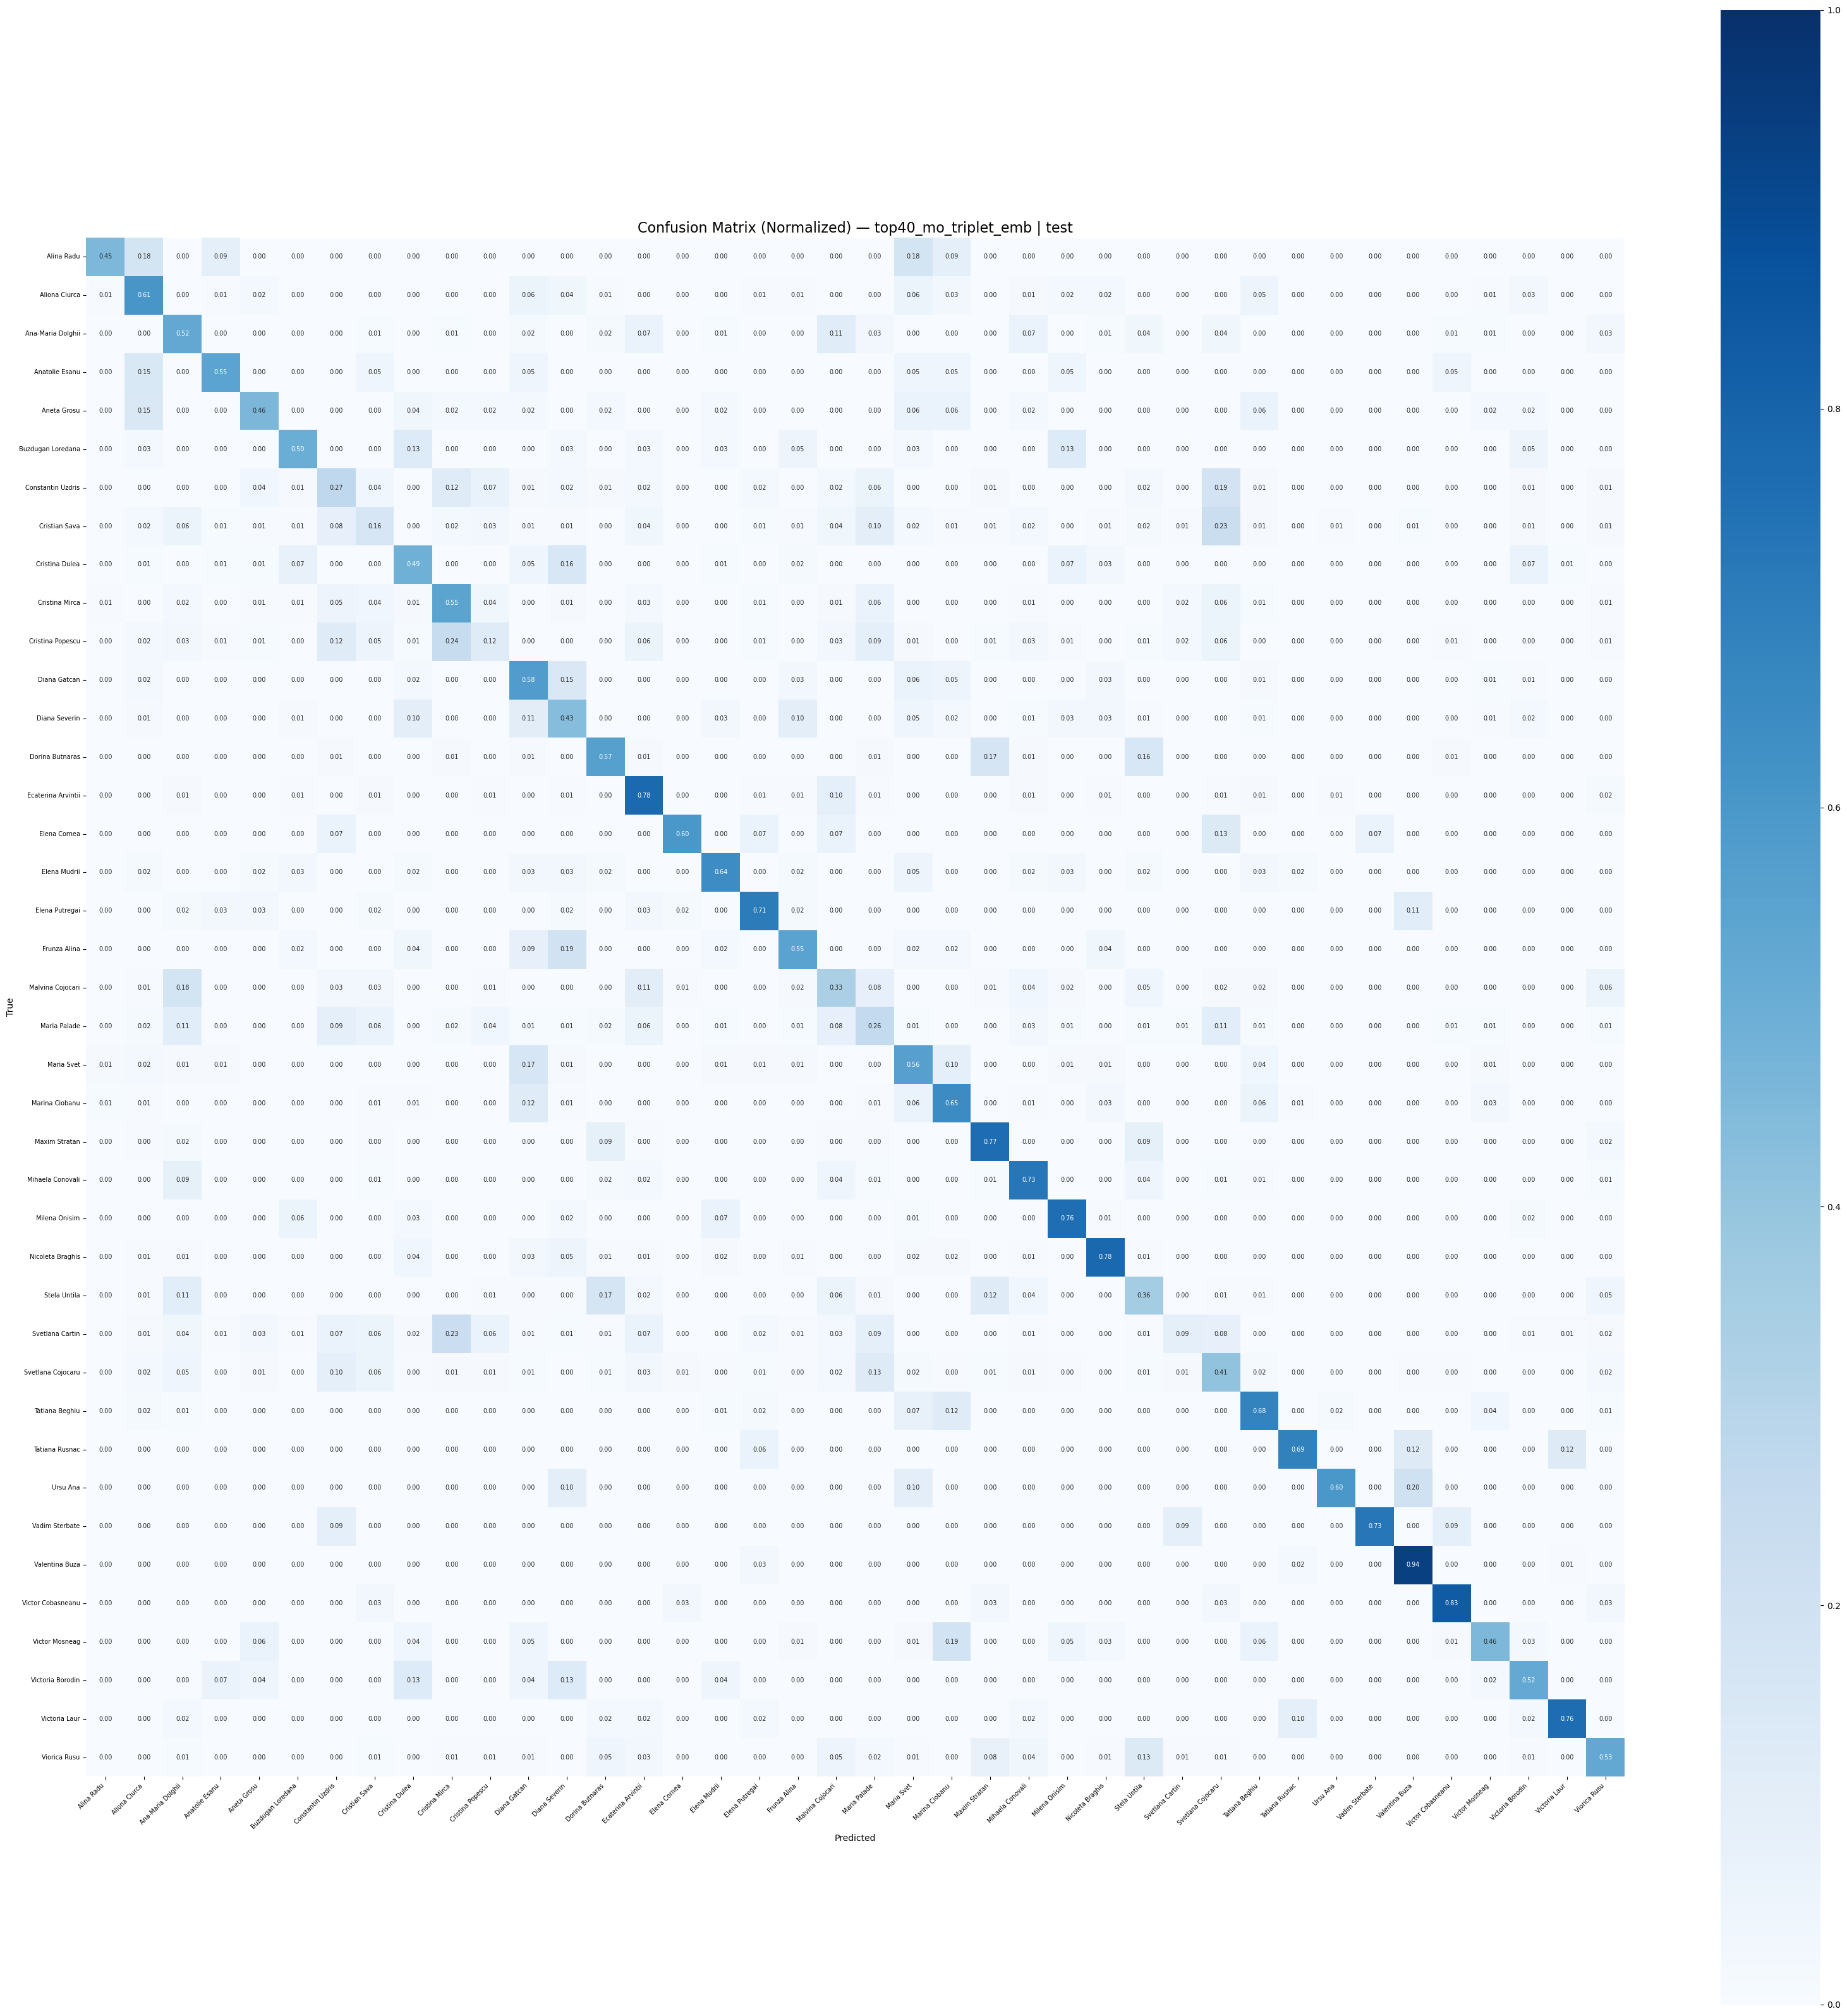


Varianta A: F1=0.5768 | Acc=0.5693
Varianta B: F1=0.5001 | Acc=0.4903


In [ ]:
# test
model_path_mo40 = "outputs_contrastive_2/top40_mo/best_triplet_top40_mo.pt"
results = evaluate_model(
    model_path_mo40, le,
    texts_test, y_test,
    dataset_name="top40_mo"
)
# 9 minute

In [61]:
# extract train doc embeddings
extract_train_doc_embeddings(
    model_path_mo40,
    train_df,
    le,
    save_path=os.path.join(
        OUTPUT_DIR,
        "top40_mo",
        "train_doc_embeddings.npz"
    ),
    tokenizer=tokenizer,
    device=device
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat: outputs_contrastive_2/top40_mo/best_triplet_top40_mo.pt
Texte train: 47215

=== Doc Embeddings (train) ===
  0/47215
  100/47215
  200/47215
  300/47215
  400/47215
  500/47215
  600/47215
  700/47215
  800/47215
  900/47215
  1000/47215
  1100/47215
  1200/47215
  1300/47215
  1400/47215
  1500/47215
  1600/47215
  1700/47215
  1800/47215
  1900/47215
  2000/47215
  2100/47215
  2200/47215
  2300/47215
  2400/47215
  2500/47215
  2600/47215
  2700/47215
  2800/47215
  2900/47215
  3000/47215
  3100/47215
  3200/47215
  3300/47215
  3400/47215
  3500/47215
  3600/47215
  3700/47215
  3800/47215
  3900/47215
  4000/47215
  4100/47215
  4200/47215
  4300/47215
  4400/47215
  4500/47215
  4600/47215
  4700/47215
  4800/47215
  4900/47215
  5000/47215
  5100/47215
  5200/47215
  5300/47215
  5400/47215
  5500/47215
  5600/47215
  5700/47215
  5800/47215
  5900/47215
  6000/47215
  6100/47215
  6200/47215
  6300/47215
  6400/47215
  6500/47215
  6600/47215
  6700/47215
  680

In [ ]:
rebuild_author_embeddings(
    model_path="outputs_contrastive_2/top40_mo/best_triplet_top40_mo.pt",
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    dataset_name="top40_mo",
    save_path="outputs_contrastive_2/top40_mo/author_embeddings_top40_mo.pt",
    tokenizer=tokenizer,
    device=device
)
# 30 minute 

Texte originale: 47215
Ferestre totale: 63722
  autor 0: 203 ferestre
  autor 1: 1892 ferestre
  autor 2: 1126 ferestre
  autor 3: 280 ferestre
  autor 4: 930 ferestre
  autor 5: 452 ferestre
  autor 6: 831 ferestre
  autor 7: 3179 ferestre
  autor 8: 1669 ferestre
  autor 9: 2883 ferestre
  autor 10: 2849 ferestre
  autor 11: 3063 ferestre
  autor 12: 3187 ferestre
  autor 13: 660 ferestre
  autor 14: 1516 ferestre
  autor 15: 143 ferestre
  autor 16: 551 ferestre
  autor 17: 759 ferestre
  autor 18: 479 ferestre
  autor 19: 1227 ferestre
  autor 20: 951 ferestre
  autor 21: 1184 ferestre
  autor 22: 2573 ferestre
  autor 23: 2155 ferestre
  autor 24: 3492 ferestre
  autor 25: 4054 ferestre
  autor 26: 1376 ferestre
  autor 27: 6863 ferestre
  autor 28: 3829 ferestre
  autor 29: 2349 ferestre
  autor 30: 1254 ferestre
  autor 31: 145 ferestre
  autor 32: 92 ferestre
  autor 33: 153 ferestre
  autor 34: 1164 ferestre
  autor 35: 364 ferestre
  autor 36: 1410 ferestre
  autor 37: 489 fe

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Alina Radu: 203 ferestre
  Aliona Ciurca: 1892 ferestre
  Ana-Maria Dolghii: 1126 ferestre
  Anatolie Esanu: 280 ferestre
  Aneta Grosu: 930 ferestre
  Buzdugan Loredana: 452 ferestre
  Constantin Uzdris: 831 ferestre
  Cristian Sava: 3179 ferestre
  Cristina Dulea: 1669 ferestre
  Cristina Mirca: 2883 ferestre
  Cristina Popescu: 2849 ferestre
  Diana Gatcan: 3063 ferestre
  Diana Severin: 3187 ferestre
  Dorina Butnaras: 660 ferestre
  Ecaterina Arvintii: 1516 ferestre
  Elena Cornea: 143 ferestre
  Elena Mudrii: 551 ferestre
  Elena Putregai: 759 ferestre
  Frunza Alina: 479 ferestre
  Malvina Cojocari: 1227 ferestre
  Maria Palade: 951 ferestre
  Maria Svet: 1184 ferestre
  Marina Ciobanu: 2573 ferestre
  Maxim Stratan: 2155 ferestre
  Mihaela Conovali: 3492 ferestre
  Milena Onisim: 4054 ferestre
  Nicoleta Braghis: 1376 ferestre
  Stela Untila: 6863 ferestre
  Svetlana Cartin: 3829 ferestre
  Svetlana Cojocaru: 2349 ferestre
  Tatiana Beghiu: 1254 ferestre
  Tatiana Rusnac: 145

In [33]:
results = implement_contrastive(
    train_df,
    val_df,
    test_df,
    "top40_mo"
)


=== Pregatire date ===
Texte originale: 47215
Ferestre totale: 63722
  autor 0: 203 ferestre
  autor 1: 1892 ferestre
  autor 2: 1126 ferestre
  autor 3: 280 ferestre
  autor 4: 930 ferestre
  autor 5: 452 ferestre
  autor 6: 831 ferestre
  autor 7: 3179 ferestre
  autor 8: 1669 ferestre
  autor 9: 2883 ferestre
  autor 10: 2849 ferestre
  autor 11: 3063 ferestre
  autor 12: 3187 ferestre
  autor 13: 660 ferestre
  autor 14: 1516 ferestre
  autor 15: 143 ferestre
  autor 16: 551 ferestre
  autor 17: 759 ferestre
  autor 18: 479 ferestre
  autor 19: 1227 ferestre
  autor 20: 951 ferestre
  autor 21: 1184 ferestre
  autor 22: 2573 ferestre
  autor 23: 2155 ferestre
  autor 24: 3492 ferestre
  autor 25: 4054 ferestre
  autor 26: 1376 ferestre
  autor 27: 6863 ferestre
  autor 28: 3829 ferestre
  autor 29: 2349 ferestre
  autor 30: 1254 ferestre
  autor 31: 145 ferestre
  autor 32: 92 ferestre
  autor 33: 153 ferestre
  autor 34: 1164 ferestre
  autor 35: 364 ferestre
  autor 36: 1410 fer

Loading weights: 0it [00:00, ?it/s]

[transformers] BertModel LOAD REPORT from: iliemihai/sentence-bert-base-romanian-uncased-v1
Key                                                            | Status     | 
---------------------------------------------------------------+------------+-
model.encoder.layer.{0...23}.intermediate.dense.bias           | UNEXPECTED | 
model.encoder.layer.{0...23}.output.LayerNorm.bias             | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.output.LayerNorm.bias   | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.value.bias         | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.output.LayerNorm.weight | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.self.query.weight       | UNEXPECTED | 
model.encoder.layer.{0...23}.attention.output.dense.weight     | UNEXPECTED | 
model.encoder.layer.{0...23}.output.dense.bias                 | UNEXPECTED | 
model.encoder.layer.{0...23}.intermediate.dense.weight         | UNEXPECTED | 
model.encoder.layer.{0...23}.output.den


==========CALCULARE PROFILE AUTORI==============


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

...

Train - loss: 0.5644 CE: 0.5148 Triplet: 0.1651 F1: 0.8717
Val  - loss: 1.4145 F1: 0.5785 Acc: 0.5686
  Salvat (F1=0.5785)

Epoch 15/15
Autori: 40
Samples per autor: 500
Total triplete: 20000
Batches (bs=40): 500
Batch size: 40
Batches per epoca: 500


/tmp/ipykernel_7572/3842971621.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_7572/3842971621.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


  Batch 0/500 loss: 0.4931 CE: 0.4464 Triplet: 0.1556
  Batch 100/500 loss: 0.6020 CE: 0.5450 Triplet: 0.1899
  Batch 200/500 loss: 0.6021 CE: 0.5508 Triplet: 0.1708
  Batch 300/500 loss: 0.4481 CE: 0.3871 Triplet: 0.2032
  Batch 400/500 loss: 0.7771 CE: 0.7281 Triplet: 0.1633


/tmp/ipykernel_7572/4053161492.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_7572/531917180.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Train - loss: 0.5527 CE: 0.5039 Triplet: 0.1626 F1: 0.8627
Val  - loss: 1.4183 F1: 0.5796 Acc: 0.5685
  Salvat (F1=0.5796)

Best Val F1: 0.5796

=== User Embeddings ===
  Alina Radu: 203 ferestre
  Aliona Ciurca: 1892 ferestre
  Ana-Maria Dolghii: 1126 ferestre
  Anatolie Esanu: 280 ferestre
  Aneta Grosu: 930 ferestre
  Buzdugan Loredana: 452 ferestre
  Constantin Uzdris: 831 ferestre
  Cristian Sava: 3179 ferestre
  Cristina Dulea: 1669 ferestre
  Cristina Mirca: 2883 ferestre
  Cristina Popescu: 2849 ferestre
  Diana Gatcan: 3063 ferestre
  Diana Severin: 3187 ferestre
  Dorina Butnaras: 660 ferestre
  Ecaterina Arvintii: 1516 ferestre
  Elena Cornea: 143 ferestre
  Elena Mudrii: 551 ferestre
  Elena Putregai: 759 ferestre
  Frunza Alina: 479 ferestre
  Malvina Cojocari: 1227 ferestre
  Maria Palade: 951 ferestre
  Maria Svet: 1184 ferestre
  Marina Ciobanu: 2573 ferestre
  Maxim Stratan: 2155 ferestre
  Mihaela Conovali: 3492 ferestre
  Milena Onisim: 4054 ferestre
  Nicoleta Bragh